**Configuration**

In [1]:
# Kaggle already ships xgboost / lightgbm / scikit-learn, so nothing needs installing.
# (If Internet is switched off in the notebook settings, pip would fail anyway.)
import xgboost, lightgbm, sklearn
print("xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__, "| scikit-learn", sklearn.__version__)


xgboost 3.4.1 | lightgbm 4.6.0 | scikit-learn 1.6.1


In [3]:
%matplotlib inline
import os

# ---------------- INPUT FILES (Kaggle dataset: rejuwanshamim/dengue-dataset) ----------------
KAGGLE_DIR = "/kaggle/input/datasets/rejuwanshamim/dengue-dataset"   # folder shown in the Kaggle "Input" panel

def find_file(name, preferred=KAGGLE_DIR):
    """Return the path of `name`: first in the expected folder, otherwise search all of /kaggle/input."""
    p = os.path.join(preferred, name)
    if os.path.exists(p): return p
    for root, _, files in os.walk("/kaggle/input"):
        if name in files: return os.path.join(root, name)
    return p                                                           # not found -> reported below

NATIONAL_CSV    = find_file("National_extract_V1_3.csv")               # OpenDengue national extract
SPATIAL_RAW_CSV = find_file("Spatial_extract_V1_3.csv")                # OpenDengue spatial (Admin1) extract
DENGAI_FILES    = ["dengue_features_train.csv", "dengue_labels_train.csv"]
DENGAI_PATHS    = [find_file(f) for f in DENGAI_FILES]

os.environ["DENGUE_CSV"] = NATIONAL_CSV
os.environ["DENGAI_DIR"] = os.path.dirname(DENGAI_PATHS[0])            # folder holding the two DengAI CSVs

# ---------------- OUTPUT LOCATIONS (/kaggle/working is the only writable, saved folder) ----------------
WORK = "/kaggle/working"
os.environ["OUT_DIR"]     = f"{WORK}/results"                          # pickles / csv / json
os.environ["FIG_DIR"]     = f"{WORK}/results/figs"                     # saved copies of every figure
os.environ["SPATIAL_PKL"] = f"{WORK}/results/admin1_weekly.pkl"        # cache built from the spatial extract
os.environ["NJOBS"]       = "-1"                                       # use all cores; set "1" for one core
for d in (os.environ["OUT_DIR"], os.environ["FIG_DIR"]): os.makedirs(d, exist_ok=True)

# ---------------- CHECK THAT EVERY FILE IS PRESENT ----------------
required = [NATIONAL_CSV, SPATIAL_RAW_CSV] + DENGAI_PATHS
missing = [p for p in required if not os.path.exists(p)]
for p in required: print(("OK       " if os.path.exists(p) else "MISSING  ") + p)
if missing:
    raise FileNotFoundError("Add the dataset 'dengue-dataset' via 'Add Input' (right sidebar) and re-run this cell. Missing: " + ", ".join(missing))


OK       /kaggle/input/datasets/rejuwanshamim/dengue-dataset/National_extract_V1_3.csv
OK       /kaggle/input/datasets/rejuwanshamim/dengue-dataset/Spatial_extract_V1_3.csv
OK       /kaggle/input/datasets/rejuwanshamim/dengue-dataset/dengue_features_train.csv
OK       /kaggle/input/datasets/rejuwanshamim/dengue-dataset/dengue_labels_train.csv


In [5]:
"""Shared helpers for the revised dengue analysis (OpenDengue V1.3 national extract)."""
import os, re, pickle, json
import numpy as np, pandas as pd
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import xgboost as xgb
import lightgbm as lgb

NJOBS = int(os.environ.get("NJOBS", "1"))            # set NJOBS=-1 on a multi-core machine
DATA = os.environ.get("DENGUE_CSV", "national.csv")  # path to OpenDengue national extract
OUT = os.environ.get("OUT_DIR", "results")
os.makedirs(OUT, exist_ok=True)
SEED = 42
TEST_FROM_YEAR = 2023        # temporal hold-out: train <= 2022, test >= 2023
NUMERIC = ["Year", "duration_days"]


def _dates(s):
    for fmt in ("%d-%m-%Y", "%Y-%m-%d"):
        try:
            return pd.to_datetime(s, format=fmt)
        except (ValueError, TypeError):
            continue
    return pd.to_datetime(s, dayfirst=True)


def load(orig=False):
    """Return X (features), y (log1p target), raw (unencoded columns for baselines/diagnostics).

    orig=True  -> exactly the authors' original pipeline (142 predictors).
    orig=False -> revised pipeline: 'confirmed'/'Confirmed' harmonised, constant S_res dropped.
    """
    df = pd.read_csv(DATA)
    df = df.drop(columns=[c for c in df.columns if df[c].isnull().all()])
    start, end = _dates(df["calendar_start_date"]), _dates(df["calendar_end_date"])
    df["duration_days"] = (end - start).dt.days
    raw = df[["adm_0_name", "Year", "dengue_total", "T_res", "case_definition_standardised", "UUID"]].copy()
    raw["start"] = start
    raw["case_definition_standardised"] = raw["case_definition_standardised"].str.strip().str.capitalize()
    d = df.drop(columns=["calendar_start_date", "calendar_end_date", "full_name", "ISO_A0",
                         "RNE_iso_code", "FAO_GAUL_code", "UUID"])
    if orig:
        cats = ["adm_0_name", "case_definition_standardised", "S_res", "T_res"]
    else:
        d["case_definition_standardised"] = d["case_definition_standardised"].str.strip().str.capitalize()
        d = d.drop(columns=["S_res"])                      # constant ("Admin0") in the national extract
        cats = ["adm_0_name", "case_definition_standardised", "T_res"]
    d = pd.get_dummies(d, columns=cats, drop_first=False, dtype=float)
    d.columns = [re.sub(r"[^A-Za-z0-9_]+", "_", c).strip("_") for c in d.columns]
    y = np.log1p(d.pop("dengue_total"))
    return d, y, raw


def feature_groups(cols):
    g = {"Country (one-hot)": [c for c in cols if c.startswith("adm_0_name_")],
         "Year": ["Year"] if "Year" in cols else [],
         "Reporting duration (days)": ["duration_days"] if "duration_days" in cols else [],
         "Temporal resolution": [c for c in cols if c.startswith("T_res_")],
         "Case definition": [c for c in cols if c.startswith("case_definition_standardised_")]}
    return {k: v for k, v in g.items() if v}


def make_pipe(model, cols):
    num = [c for c in NUMERIC if c in cols]
    if num:
        ct = ColumnTransformer([("num", StandardScaler(), num)], remainder="passthrough",
                               verbose_feature_names_out=False)
    else:
        ct = "passthrough"
    return Pipeline([("prep", ct), ("model", model)])


def pipe_feature_names(cols):
    num = [c for c in NUMERIC if c in cols]
    return num + [c for c in cols if c not in num]


def default_models():
    return {
        "Linear Regression": LinearRegression(),
        "SVR": SVR(),
        "k-NN": KNeighborsRegressor(),
        "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
        "XGBoost": xgb.XGBRegressor(random_state=SEED, n_jobs=NJOBS),
        "LightGBM": lgb.LGBMRegressor(random_state=SEED, verbose=-1, n_jobs=NJOBS),
        "Random Forest": RandomForestRegressor(random_state=SEED, n_jobs=NJOBS),
    }


def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = y - p
    return dict(
        R2=r2_score(y, p), MAE=float(np.abs(e).mean()), MSE=float((e ** 2).mean()),
        RMSE=float(np.sqrt((e ** 2).mean())),
        Spearman=float(spearmanr(y, p)[0]),
        within_x2=float((np.abs(e) <= np.log(2)).mean()),
        within_x10=float((np.abs(e) <= np.log(10)).mean()),
        MAE_cases=float(mean_absolute_error(np.expm1(y), np.expm1(np.clip(p, 0, None)))),
    )


def baseline_predictions(raw_tr, ytr, raw_te, recent_years=None):
    """Naive (no-ML) baselines computed on the training rows only, in log space."""
    tr = raw_tr.assign(y=np.asarray(ytr))
    gm = tr["y"].mean()
    cm = tr.groupby("adm_0_name")["y"].mean()
    ctm = tr.groupby(["adm_0_name", "T_res"])["y"].mean()
    rm = tr.groupby("T_res")["y"].mean()
    p_c = raw_te["adm_0_name"].map(cm).fillna(gm).to_numpy()
    p_ct = np.array([ctm.get((a, b), np.nan) for a, b in zip(raw_te["adm_0_name"], raw_te["T_res"])])
    p_ct = np.where(np.isnan(p_ct), p_c, p_ct)
    out = {"Global mean": np.full(len(raw_te), gm),
           "Country mean": p_c,
           "Country x resolution mean": p_ct,
           "Resolution mean": raw_te["T_res"].map(rm).fillna(gm).to_numpy()}
    if recent_years is not None:
        rec = tr[tr["Year"] >= tr["Year"].max() - recent_years + 1]
        rctm = rec.groupby(["adm_0_name", "T_res"])["y"].mean()
        p_r = np.array([rctm.get((a, b), np.nan) for a, b in zip(raw_te["adm_0_name"], raw_te["T_res"])])
        out["Recent country x resolution mean"] = np.where(np.isnan(p_r), p_ct, p_r)
    return out


def cluster_bootstrap(y, preds, clusters, B=2000, seed=0, pairs=()):
    """Country-cluster bootstrap CIs for R2 and MAE (log scale); pairs -> paired differences."""
    y = np.asarray(y, float)
    codes, uniq = pd.factorize(pd.Series(np.asarray(clusters)))
    K = len(uniq)
    def stats(p):
        e = y - np.asarray(p, float)
        S = np.zeros((K, 5))
        np.add.at(S[:, 0], codes, 1.0); np.add.at(S[:, 1], codes, y); np.add.at(S[:, 2], codes, y * y)
        np.add.at(S[:, 3], codes, e * e); np.add.at(S[:, 4], codes, np.abs(e))
        return S
    rng = np.random.default_rng(seed)
    W = rng.multinomial(K, np.ones(K) / K, size=B).astype(float)     # B x K cluster weights
    def r2_mae(S):
        T = W @ S
        sst = T[:, 2] - T[:, 1] ** 2 / T[:, 0]
        return 1 - T[:, 3] / sst, T[:, 4] / T[:, 0]
    res, cache = {}, {}
    for name, p in preds.items():
        r2, mae = r2_mae(stats(p)); cache[name] = (r2, mae)
        res[name] = {"R2_lo": float(np.percentile(r2, 2.5)), "R2_hi": float(np.percentile(r2, 97.5)),
                     "MAE_lo": float(np.percentile(mae, 2.5)), "MAE_hi": float(np.percentile(mae, 97.5))}
    diffs = {}
    for a, b in pairs:
        d_r2 = cache[a][0] - cache[b][0]; d_mae = cache[a][1] - cache[b][1]
        diffs[f"{a} minus {b}"] = {"dR2_lo": float(np.percentile(d_r2, 2.5)), "dR2_hi": float(np.percentile(d_r2, 97.5)),
                                   "dMAE_lo": float(np.percentile(d_mae, 2.5)), "dMAE_hi": float(np.percentile(d_mae, 97.5))}
    return res, diffs


def save(obj, name):
    with open(os.path.join(OUT, name), "wb") as f:
        pickle.dump(obj, f)


def loadp(name):
    with open(os.path.join(OUT, name), "rb") as f:
        return pickle.load(f)

## 1. Data audit (numbers quoted in the paper)

In [6]:
df0 = pd.read_csv(DATA)
print("records:", len(df0), "| countries/territories:", df0.adm_0_name.nunique(), "| years:", df0.Year.min(), "-", df0.Year.max())
print("share of exact zeros: %.3f" % (df0.dengue_total == 0).mean())
print(df0.T_res.value_counts().to_string()); print(df0.case_definition_standardised.value_counts().to_string())
print("median cases:", df0.dengue_total.median(), "| max:", df0.dengue_total.max(), "| total:", int(df0.dengue_total.sum()))
print(df0.groupby("Year").dengue_total.agg(total="sum", records="size").loc[[2016, 2019, 2020, 2023, 2024, 2025]])

records: 29873 | countries/territories: 129 | years: 1924 - 2025
share of exact zeros: 0.326
T_res
Week     23248
Year      3495
Month     3130
case_definition_standardised
Total                      23592
Suspected                   3295
Confirmed                   1307
Probable and confirmed      1074
Suspected and confirmed      399
Probable                     103
confirmed                    103
median cases: 28.0 | max: 10267077.0 | total: 76817159
           total  records
Year                     
2016   3908258.0     1652
2019   5068898.0     2525
2020   3092230.0     1583
2023   6327346.0     3065
2024  14363035.0     1643
2025     54748.0      104


In [7]:
import sys, time, json, warnings

import numpy as np, pandas as pd

from sklearn.model_selection import train_test_split, GroupKFold, RandomizedSearchCV, KFold

from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")

T0 = time.time()

def log(*a): print(f"[{time.time()-T0:7.0f}s]", *a, flush=True)

def fit_predict(model, Xtr, ytr, Xte):
    pipe = make_pipe(model, list(Xtr.columns)).fit(Xtr, ytr)
    return pipe, pipe.predict(Xte)

SPACES = {
    "Random Forest": ({"n_estimators": [100, 200, 300, 400, 500], "max_features": ["sqrt", "log2", 0.8],
                       "max_depth": [10, 20, 30, None], "min_samples_split": [2, 5, 10, 20],
                       "min_samples_leaf": [1, 2, 4, 8]}, 12),                      # same space as original paper
    "Gradient Boosting": ({"n_estimators": [100, 200, 300], "learning_rate": [0.03, 0.05, 0.1, 0.2],
                           "max_depth": [3, 4, 5, 6], "subsample": [0.7, 1.0], "min_samples_leaf": [1, 5, 20]}, 12),
    "XGBoost": ({"n_estimators": [200, 400, 600], "learning_rate": [0.03, 0.05, 0.1], "max_depth": [3, 4, 6, 8],
                 "subsample": [0.7, 1.0], "colsample_bytree": [0.5, 0.8, 1.0], "min_child_weight": [1, 5, 10],
                 "reg_lambda": [1, 5, 10]}, 12),
    "LightGBM": ({"n_estimators": [200, 400, 600], "learning_rate": [0.03, 0.05, 0.1], "num_leaves": [15, 31, 63, 127],
                  "min_child_samples": [5, 20, 50], "subsample": [0.7, 1.0], "subsample_freq": [1],
                  "colsample_bytree": [0.5, 0.8, 1.0], "reg_lambda": [0, 5]}, 12),
    "k-NN": ({"n_neighbors": [3, 5, 10, 20, 50], "weights": ["uniform", "distance"], "p": [1, 2]}, 12),
    "SVR": ({"C": [0.5, 1, 3, 10], "epsilon": [0.1]}, 4),                         # reduced budget (slow kernel)
}

def group_perm_importance(pipe, Xte, yte, groups, n_repeats=5, seed=0):
    rng = np.random.RandomState(seed)
    base = r2_score(yte, pipe.predict(Xte)); out = {}
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = Xte.copy(); perm = rng.permutation(len(Xp))
            Xp[cols] = Xte[cols].to_numpy()[perm]
            drops.append(base - r2_score(yte, pipe.predict(Xp)))
        out[g] = (float(np.mean(drops)), float(np.std(drops)))
    return base, out

In [10]:
def temporal_split(raw):
    tr = np.where(raw["Year"].to_numpy() < TEST_FROM_YEAR)[0]
    te = np.where(raw["Year"].to_numpy() >= TEST_FROM_YEAR)[0]
    return tr, te

## 2. Reproduce the ORIGINAL result (random 80/20 split, seed 42, 142 predictors)

In [11]:
def stage_repro():
    """Re-run the authors' ORIGINAL pipeline (142 predictors, random 80/20 split, seed 42)."""
    X, y, raw = load(orig=True)
    tr, te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=SEED)
    res = {"n_predictors": X.shape[1], "n_train": len(tr), "n_test": len(te)}
    for name, m in default_models().items():
        _, p = fit_predict(m, X.iloc[tr], y.iloc[tr], X.iloc[te])
        res[name] = metrics(y.iloc[te], p); log("repro", name, round(res[name]["R2"], 4))
    json.dump(res, open(f"{OUT}/repro.json", "w"), indent=1)

In [12]:
T0 = time.time()
stage_repro()

[      0s] repro Linear Regression 0.7742
[     77s] repro SVR 0.8119
[     78s] repro k-NN 0.8704
[     82s] repro Gradient Boosting 0.601
[     82s] repro XGBoost 0.8513
[     83s] repro LightGBM 0.834
[     88s] repro Random Forest 0.8791


## 3. Protocol A — random 80/20 split (harmonised pipeline) + baselines

In [15]:
def stage_random():
    X, y, raw = load()
    tr, te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=SEED)
    preds, res = {}, {}
    for name, m in default_models().items():
        _, p = fit_predict(m, X.iloc[tr], y.iloc[tr], X.iloc[te]); preds[name] = p
        log("random", name, round(r2_score(y.iloc[te], p), 4))
    preds.update(baseline_predictions(raw.iloc[tr], y.iloc[tr], raw.iloc[te]))
    for k, p in preds.items(): res[k] = metrics(y.iloc[te], p)
    save({"te": te, "tr": tr, "preds": preds, "metrics": res}, "random.pkl")

In [16]:
T0 = time.time()
stage_random()

[      0s] random Linear Regression 0.7742
[     69s] random SVR 0.8162
[     70s] random k-NN 0.8694
[     73s] random Gradient Boosting 0.6008
[     74s] random XGBoost 0.851
[     74s] random LightGBM 0.834
[     80s] random Random Forest 0.8788


## 4. Protocol B — temporal hold-out (train ≤ 2022, test 2023-2025): default models + baselines

In [17]:
def stage_temporal():
    X, y, raw = load()
    tr, te = temporal_split(raw)
    preds, res = {}, {}
    for name, m in default_models().items():
        _, p = fit_predict(m, X.iloc[tr], y.iloc[tr], X.iloc[te]); preds[name] = p
        log("temporal", name, round(r2_score(y.iloc[te], p), 4))
    preds.update(baseline_predictions(raw.iloc[tr], y.iloc[tr], raw.iloc[te], recent_years=2))
    for k, p in preds.items(): res[k] = metrics(y.iloc[te], p)
    save({"te": te, "tr": tr, "preds": preds, "metrics": res}, "temporal.pkl")

In [18]:
T0 = time.time()
stage_temporal()

[      0s] temporal Linear Regression 0.6939
[     68s] temporal SVR 0.6337
[     69s] temporal k-NN 0.569
[     72s] temporal Gradient Boosting 0.4848
[     72s] temporal XGBoost 0.6513
[     72s] temporal LightGBM 0.6125
[     78s] temporal Random Forest 0.4788


## 5. Equal-budget hyper-parameter tuning in protocol B (expanding-window CV inside the training years)

In [24]:
def stage_tune():
    X, y, raw = load()
    tr, te = temporal_split(raw)
    Xtr, ytr, Xte, yte = X.iloc[tr], y.iloc[tr], X.iloc[te], y.iloc[te]
    yrs = raw["Year"].to_numpy()[tr]
    folds = [(np.where(yrs < v)[0], np.where(yrs == v)[0]) for v in (2020, 2021, 2022)]   # expanding window
    base = default_models(); out = {"best": {}, "cv": {}, "preds": {}, "metrics": {}, "seconds": {}}
    for name, (space, n_iter) in SPACES.items():
        t = time.time()
        pipe = make_pipe(base[name], list(Xtr.columns))
        rs = RandomizedSearchCV(pipe, {f"model__{k}": v for k, v in space.items()}, n_iter=n_iter, cv=folds,
                                scoring="r2", random_state=SEED, n_jobs=1, refit=True)
        rs.fit(Xtr, ytr)
        p = rs.best_estimator_.predict(Xte)
        out["best"][name] = {k.replace("model__", ""): (None if v is None else (v.item() if hasattr(v, "item") else v))
                             for k, v in rs.best_params_.items()}
        out["cv"][name] = float(rs.best_score_); out["preds"][name] = p
        out["metrics"][name] = metrics(yte, p); out["seconds"][name] = time.time() - t
        log("tune", name, "cvR2", round(rs.best_score_, 4), "testR2", round(out["metrics"][name]["R2"], 4), out["best"][name])
        if name == "Random Forest":
            groups = feature_groups(list(Xtr.columns))
            b, imp = group_perm_importance(rs.best_estimator_, Xte, yte, groups)
            gini = rs.best_estimator_.named_steps["model"].feature_importances_
            out["perm_tuned_rf_temporal"] = {"base_R2": b, "imp": imp}
            out["gini_tuned_rf"] = dict(zip(pipe_feature_names(list(Xtr.columns)), gini))
    save(out, "tune.pkl")

In [25]:
T0 = time.time()
stage_tune()

[    153s] tune Random Forest cvR2 0.7206 testR2 0.6026 {'n_estimators': 200, 'min_samples_split': 20, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None}
[    354s] tune Gradient Boosting cvR2 0.749 testR2 0.6665 {'subsample': 0.7, 'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 4, 'learning_rate': 0.1}
[    393s] tune XGBoost cvR2 0.7629 testR2 0.6814 {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.5}
[    433s] tune LightGBM cvR2 0.751 testR2 0.6598 {'subsample_freq': 1, 'subsample': 0.7, 'reg_lambda': 5, 'num_leaves': 15, 'n_estimators': 600, 'min_child_samples': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
[    540s] tune k-NN cvR2 0.7307 testR2 0.5823 {'weights': 'distance', 'p': 1, 'n_neighbors': 50}
[   1084s] tune SVR cvR2 0.7528 testR2 0.6358 {'epsilon': 0.1, 'C': 0.5}


## 6. Protocol C — leave-country-out (5-fold GroupKFold by country)

In [26]:
def stage_loco():
    X, y, raw = load()
    gkf = GroupKFold(n_splits=5)
    groups = raw["adm_0_name"].to_numpy()
    preds = {k: np.zeros(len(X)) for k in list(default_models()) + ["Global mean", "Resolution mean"]}
    folds = []
    for i, (tr, te) in enumerate(gkf.split(X, y, groups)):
        folds.append(te)
        for name, m in default_models().items():
            _, p = fit_predict(m, X.iloc[tr], y.iloc[tr], X.iloc[te]); preds[name][te] = p
        b = baseline_predictions(raw.iloc[tr], y.iloc[tr], raw.iloc[te])
        preds["Global mean"][te] = b["Global mean"]; preds["Resolution mean"][te] = b["Resolution mean"]
        log("loco fold", i, "n_test", len(te), "countries", len(set(groups[te])))
    res = {k: metrics(y, p) for k, p in preds.items()}
    save({"preds": preds, "metrics": res, "folds": folds}, "loco.pkl")

In [27]:
T0 = time.time()
stage_loco()

[     81s] loco fold 0 n_test 5976 countries 26
[    158s] loco fold 1 n_test 5976 countries 26
[    239s] loco fold 2 n_test 5970 countries 25
[    317s] loco fold 3 n_test 5976 countries 26
[    394s] loco fold 4 n_test 5975 countries 26


## 7. Ten repeated random splits (how much does the seed matter?)

In [28]:
def stage_seeds():
    X, y, raw = load(); rows = []
    for seed in range(10):
        tr, te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=seed)
        for name in ["Linear Regression", "LightGBM", "Random Forest"]:
            _, p = fit_predict(default_models()[name], X.iloc[tr], y.iloc[tr], X.iloc[te])
            rows.append({"seed": seed, "model": name, **metrics(y.iloc[te], p)})
        b = baseline_predictions(raw.iloc[tr], y.iloc[tr], raw.iloc[te])
        for k in ["Country mean", "Country x resolution mean"]:
            rows.append({"seed": seed, "model": k, **metrics(y.iloc[te], b[k])})
        log("seeds", seed)
    pd.DataFrame(rows).to_csv(f"{OUT}/seeds.csv", index=False)

In [29]:
T0 = time.time()
stage_seeds()

[      7s] seeds 0
[     14s] seeds 1
[     20s] seeds 2
[     27s] seeds 3
[     33s] seeds 4
[     39s] seeds 5
[     46s] seeds 6
[     53s] seeds 7
[     59s] seeds 8
[     66s] seeds 9


## 8. Feature-set ablation (what is the model actually using?)

In [32]:
def stage_ablate():
    X, y, raw = load(); G = feature_groups(list(X.columns))
    sets = {"Year only": G["Year"], "Resolution only (T_res + duration)": G["Temporal resolution"] + G["Reporting duration (days)"],
            "Country only": G["Country (one-hot)"],
            "Country + resolution": G["Country (one-hot)"] + G["Temporal resolution"] + G["Reporting duration (days)"],
            "Country + resolution + case definition": G["Country (one-hot)"] + G["Temporal resolution"] + G["Reporting duration (days)"] + G["Case definition"],
            "All features (incl. Year)": list(X.columns)}
    rtr, rte = train_test_split(np.arange(len(X)), test_size=0.2, random_state=SEED)
    ttr, tte = temporal_split(raw); rows = []
    for nm, cols in sets.items():
        for proto, (tr, te) in {"Random split": (rtr, rte), "Temporal hold-out": (ttr, tte)}.items():
            m = RandomForestRegressor(random_state=SEED, n_jobs=NJOBS)
            _, p = fit_predict(m, X.iloc[tr][cols], y.iloc[tr], X.iloc[te][cols])
            rows.append({"features": nm, "protocol": proto, **metrics(y.iloc[te], p)})
        log("ablate", nm)
    pd.DataFrame(rows).to_csv(f"{OUT}/ablation.csv", index=False)

In [33]:
T0 = time.time()
stage_ablate()

[      1s] ablate Year only
[      1s] ablate Resolution only (T_res + duration)
[     16s] ablate Country only
[     26s] ablate Country + resolution
[     35s] ablate Country + resolution + case definition
[     47s] ablate All features (incl. Year)


## 9. Feature importance: Gini and grouped permutation importance

In [35]:
def stage_importance():
    """Default RF on the ORIGINAL random split: Gini + grouped permutation importance."""
    X, y, raw = load()
    tr, te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=SEED)
    pipe, _ = fit_predict(RandomForestRegressor(random_state=SEED, n_jobs=NJOBS), X.iloc[tr], y.iloc[tr], X.iloc[te])
    names = pipe_feature_names(list(X.columns)); gini = pipe.named_steps["model"].feature_importances_
    G = feature_groups(list(X.columns)); b, imp = group_perm_importance(pipe, X.iloc[te], y.iloc[te], G)
    gsum = {g: float(sum(gini[names.index(c)] for c in cols)) for g, cols in G.items()}
    top = sorted(zip(names, gini), key=lambda t: -t[1])[:20]
    save({"base_R2": b, "perm": imp, "gini_group": gsum, "gini_top20": top}, "importance_random.pkl")
    log("importance", gsum)

In [36]:
T0 = time.time()
stage_importance()

[      8s] importance {'Country (one-hot)': 0.7288202524140038, 'Year': 0.13460239504073523, 'Reporting duration (days)': 0.014851062358887968, 'Temporal resolution': 0.04005153325651143, 'Case definition': 0.08167475692986126}


## 10. Rolling-origin evaluation (test year 2016 … 2024)

In [45]:
def stage_rolling():
    """Rolling-origin evaluation: for each test year v (2016-2024) train on all years < v."""
    X, y, raw = load(); rows = []
    yrs = raw["Year"].to_numpy()
    noyear = [c for c in X.columns if c != "Year"]
    for v in range(2016, 2025):
        tr, te = np.where(yrs < v)[0], np.where(yrs == v)[0]
        preds = {}
        for name in ["Linear Regression", "k-NN", "XGBoost", "LightGBM", "Random Forest"]:
            _, preds[name] = fit_predict(default_models()[name], X.iloc[tr], y.iloc[tr], X.iloc[te])
        for name in ["LightGBM", "Random Forest"]:
            _, preds[name + " (no Year)"] = fit_predict(default_models()[name], X.iloc[tr][noyear], y.iloc[tr], X.iloc[te][noyear])
        b = baseline_predictions(raw.iloc[tr], y.iloc[tr], raw.iloc[te])
        preds["Country mean"], preds["Country x resolution mean"] = b["Country mean"], b["Country x resolution mean"]
        for k, p in preds.items(): rows.append({"test_year": v, "n_test": len(te), "model": k, **metrics(y.iloc[te], p)})
        log("rolling", v, len(te))
    pd.DataFrame(rows).to_csv(f"{OUT}/rolling.csv", index=False)

In [46]:
T0 = time.time()
stage_rolling()

[      6s] rolling 2016 1652
[     12s] rolling 2017 2329
[     20s] rolling 2018 2528
[     28s] rolling 2019 2525
[     37s] rolling 2020 1583
[     47s] rolling 2021 2329
[     58s] rolling 2022 2782
[     70s] rolling 2023 3065
[     84s] rolling 2024 1643


## 11. Accuracy on large outbreaks

In [49]:
def stage_extreme():
    """Accuracy on large outbreaks (>=10,000 reported cases in one reporting period), temporal test set."""
    X, y, raw = load(); tmp, tun = loadp("temporal.pkl"), loadp("tune.pkl")
    te = tmp["te"]; obs = raw["dengue_total"].iloc[te].to_numpy(); yt = y.iloc[te].to_numpy()
    preds = {"Random Forest (tuned)": tun["preds"]["Random Forest"], "Random Forest": tmp["preds"]["Random Forest"],
             "Linear Regression": tmp["preds"]["Linear Regression"], "XGBoost": tmp["preds"]["XGBoost"],
             "Country x resolution mean": tmp["preds"]["Country x resolution mean"]}
    out = {}
    for thr in (1000, 10000, 100000):
        m = obs >= thr; d = {"n": int(m.sum())}
        for k, p in preds.items():
            e = yt[m] - p[m]
            d[k] = {"median_pred_over_obs": float(np.median(np.expm1(np.clip(p[m], 0, None)) / obs[m])),
                    "share_within_x2": float((np.abs(e) <= np.log(2)).mean()), "share_underpredicted": float((e > 0).mean()),
                    "MAE_log": float(np.abs(e).mean())}
        out[f">={thr}"] = d
    save(out, "extreme.pkl"); log("extreme", {k: v["n"] for k, v in out.items()})

In [50]:
T0 = time.time()
stage_extreme()

[      0s] extreme {'>=1000': 753, '>=10000': 156, '>=100000': 22}


## 11b. Paired bootstrap: tuned models vs baseline (protocol B)

In [51]:
def stage_extra():
    """Protocol B: paired country-cluster bootstrap of tuned models against the baseline and linear regression."""
    X, y, raw = load(); tmp, tun = loadp("temporal.pkl"), loadp("tune.pkl")
    te = tmp["te"]; yt = y.iloc[te].to_numpy()
    P = {"cxr": tmp["preds"]["Country x resolution mean"], "LR": tmp["preds"]["Linear Regression"]}
    for k in ["XGBoost", "Gradient Boosting", "LightGBM", "SVR"]: P[k + " (tuned)"] = tun["preds"][k]
    pairs = [(k, "cxr") for k in P if "tuned" in k] + [(k, "LR") for k in P if "tuned" in k]
    _, d = cluster_bootstrap(yt, P, raw["adm_0_name"].iloc[te], pairs=pairs)
    json.dump({k.replace("cxr", "cxr"): v for k, v in d.items()}, open(f"{OUT}/extra_pairs.json", "w"), indent=1)
    log("extra done")

In [52]:
T0 = time.time()
stage_extra()

[      0s] extra done


## 12. Diagnostics: leakage statistics, bootstrap CIs, seen/unseen countries, zeros

In [54]:
def stage_diag():
    X, y, raw = load()
    rnd, tmp, tun, loco = loadp("random.pkl"), loadp("temporal.pkl"), loadp("tune.pkl"), loadp("loco.pkl")
    out = {}
    # ---- leakage statistics ----------------------------------------------------------------
    def leak(tr, te):
        cy_tr = set(zip(raw["adm_0_name"].iloc[tr], raw["Year"].iloc[tr]))
        cy_share = np.mean([(a, b) in cy_tr for a, b in zip(raw["adm_0_name"].iloc[te], raw["Year"].iloc[te])])
        w = raw.iloc[te]; w = w[w["T_res"] == "Week"]
        trs = set(zip(raw["adm_0_name"].iloc[tr], raw["start"].iloc[tr]))
        nb = np.mean([((a, s - pd.Timedelta(days=7)) in trs) or ((a, s + pd.Timedelta(days=7)) in trs)
                      for a, s in zip(w["adm_0_name"], w["start"])])
        return {"country_year_in_train": float(cy_share), "weekly_adjacent_week_in_train": float(nb)}
    out["leak_random"] = leak(rnd["tr"], rnd["te"]); out["leak_temporal"] = leak(tmp["tr"], tmp["te"])
    # ---- bootstrap CIs -----------------------------------------------------------------------
    yr, yt = y.iloc[rnd["te"]].to_numpy(), y.iloc[tmp["te"]].to_numpy()
    tpreds = dict(tmp["preds"]); tpreds.update({f"{k} (tuned)": v for k, v in tun["preds"].items()})
    pairs_t = [("Random Forest (tuned)", "Random Forest"), ("Random Forest (tuned)", "Linear Regression"),
               ("Random Forest (tuned)", "Country x resolution mean"), ("Linear Regression", "Country x resolution mean"),
               ("LightGBM (tuned)", "Linear Regression"), ("Random Forest", "Linear Regression")]
    out["boot_temporal"] = cluster_bootstrap(yt, tpreds, raw["adm_0_name"].iloc[tmp["te"]], pairs=pairs_t)
    out["boot_random"] = cluster_bootstrap(yr, rnd["preds"], raw["adm_0_name"].iloc[rnd["te"]],
                                           pairs=[("Random Forest", "Linear Regression"), ("Random Forest", "Country x resolution mean"),
                                                  ("Linear Regression", "Country x resolution mean")])
    out["boot_loco"] = cluster_bootstrap(y.to_numpy(), loco["preds"], raw["adm_0_name"], pairs=[("Random Forest", "Resolution mean"), ("Linear Regression", "Resolution mean")])
    # ---- breakdowns for the temporal test set ------------------------------------------------
    te = tmp["te"]; tr = tmp["tr"]; rte = raw.iloc[te]
    seen = rte["adm_0_name"].isin(raw["adm_0_name"].iloc[tr]).to_numpy(); zero = (rte["dengue_total"].to_numpy() == 0)
    bd = {}
    for name, p in tpreds.items():
        e = yt - p
        bd[name] = {"R2_seen": r2_score(yt[seen], p[seen]), "MAE_seen": float(np.abs(e[seen]).mean()),
                    "MAE_unseen": float(np.abs(e[~seen]).mean()),
                    "MAE_zero": float(np.abs(e[zero]).mean()), "MAE_positive": float(np.abs(e[~zero]).mean()),
                    "mean_pred_zero": float(p[zero].mean())}
    out["breakdown"] = bd
    out["counts"] = {"n_test": int(len(te)), "n_unseen_rows": int((~seen).sum()),
                     "n_unseen_countries": int(rte.loc[~seen, "adm_0_name"].nunique()),
                     "zero_share_test": float(zero.mean()), "zero_share_all": float((raw["dengue_total"] == 0).mean()),
                     "zero_share_by_year": rte.assign(z=zero).groupby("Year")["z"].mean().to_dict()}
    save(out, "diag.pkl"); log("diag done")

In [55]:
T0 = time.time()
stage_diag()

[      0s] diag done


## 12b. Robustness: 5-fold cross-validation of Protocol A — Section 4.9

In [56]:
def stage_kfold():
    """5-fold CV (Protocol A companion): same model set, non-overlapping folds, mean +/- SD across folds."""
    X, y, raw = load(); kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    rows = []; fold_metrics = {name: [] for name in list(default_models()) + ["Country mean", "Country x resolution mean"]}
    for fold, (tr, te) in enumerate(kf.split(X)):
        for name, m in default_models().items():
            _, p = fit_predict(m, X.iloc[tr], y.iloc[tr], X.iloc[te])
            fold_metrics[name].append(metrics(y.iloc[te], p))
        b = baseline_predictions(raw.iloc[tr], y.iloc[tr], raw.iloc[te])
        for k in ["Country mean", "Country x resolution mean"]:
            fold_metrics[k].append(metrics(y.iloc[te], b[k]))
        log("kfold", fold, "done")
    summary = {}
    for name, ms in fold_metrics.items():
        r2s = np.array([m["R2"] for m in ms]); maes = np.array([m["MAE"] for m in ms])
        summary[name] = {"R2_mean": float(r2s.mean()), "R2_sd": float(r2s.std()), "R2_folds": r2s.tolist(),
                         "MAE_mean": float(maes.mean()), "MAE_sd": float(maes.std())}
    save(summary, "kfold.pkl"); log("kfold summary", {k: round(v["R2_mean"], 4) for k, v in summary.items()})

In [57]:
T0 = time.time()
stage_kfold()

[     78s] kfold 0 done
[    158s] kfold 1 done
[    237s] kfold 2 done
[    314s] kfold 3 done
[    393s] kfold 4 done
[    393s] kfold summary {'Linear Regression': 0.7727, 'SVR': 0.8169, 'k-NN': 0.8132, 'Gradient Boosting': 0.5943, 'XGBoost': 0.8504, 'LightGBM': 0.825, 'Random Forest': 0.8721, 'Country mean': 0.7308, 'Country x resolution mean': 0.7646}


## 13. Figures

In [58]:
import json, os

import numpy as np, pandas as pd

import matplotlib.pyplot as plt

from matplotlib.patches import FancyBboxPatch

from scipy.stats import kurtosis

FIG = os.environ.get("FIG_DIR", os.path.join(OUT, "figs")); os.makedirs(FIG, exist_ok=True)

plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "axes.labelsize": 9, "figure.dpi": 100, "savefig.dpi": 200,
                     "savefig.bbox": "tight"})

C_BASE, C_ML, C_RF, C_TUN, C_ZERO, C_POS = "#8c8c8c", "#4C72B0", "#C44E52", "#DD8452", "#C44E52", "#4C72B0"

X, y, raw = load()

rnd, tmp, tun, loco = loadp("random.pkl"), loadp("temporal.pkl"), loadp("tune.pkl"), loadp("loco.pkl")

diag, imp_r = loadp("diag.pkl"), loadp("importance_random.pkl")

seeds, abl = pd.read_csv(f"{OUT}/seeds.csv"), pd.read_csv(f"{OUT}/ablation.csv")

ML = ["Linear Regression", "k-NN", "SVR", "Gradient Boosting", "XGBoost", "LightGBM", "Random Forest"]

SHOW = [("Random Forest (tuned)", tun["preds"]["Random Forest"]), ("Linear Regression", tmp["preds"]["Linear Regression"])]

In [59]:
def fig1():
    fig, ax = plt.subplots(figsize=(9, 4.4)); ax.set_xlim(0, 100); ax.set_ylim(0, 50); ax.axis("off")
    def box(x, yy, w, h, txt, fc="#EAF0F8", ec="#4C72B0", fs=8.2, bold=False):
        ax.add_patch(FancyBboxPatch((x, yy), w, h, boxstyle="round,pad=0.4,rounding_size=1.2", fc=fc, ec=ec, lw=1.2))
        ax.text(x + w / 2, yy + h / 2, txt, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal")
    def arrow(x1, y1, x2, y2):
        ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.2))
    box(1, 38, 22, 9, "OpenDengue V1.3\nnational extract\n29,873 records\n129 countries/territories", bold=True)
    box(28, 38, 22, 9, "Cleaning & features\n140 predictors: country,\nresolution, case definition,\nYear, duration")
    box(55, 38, 20, 9, "Target\nlog(1 + reported cases)\n32.6% zeros")
    box(80, 38, 19, 9, "Naive baselines\n(country / resolution\nmeans, no ML)", fc="#F2F2F2", ec="#8c8c8c")
    arrow(23.5, 42.5, 27.5, 42.5); arrow(50.5, 42.5, 54.5, 42.5); arrow(75.5, 42.5, 79.5, 42.5)
    box(1, 19, 31, 12, "A  Random 80/20 split (seed 42)\nconventional protocol;\nalso 10 repeated seeds", fc="#FBEFEF", ec="#C44E52")
    box(35, 19, 31, 12, "B  Temporal hold-out (primary)\ntrain: 1924-2022 (25,061)\ntest: 2023-2025 (4,812)", fc="#EAF6EA", ec="#55A868", bold=True)
    box(69, 19, 30, 12, "C  Leave-country-out\n5-fold GroupKFold by country\n(129 countries)", fc="#FFF5E0", ec="#DD8452")
    for xx in (16.5, 50.5, 84):
        arrow(65, 37.5, xx, 31.5)
    box(1, 2, 45, 12, "Models: linear, k-NN, SVR, Gradient Boosting,\nXGBoost, LightGBM, Random Forest\n(default; equal-budget random-search tuning\nwith expanding-window CV in protocol B)")
    box(52, 2, 47, 12, "Evaluation: R², MAE, RMSE (log scale), rank correlation,\nshare within ×2 / ×10, MAE in cases;\ncountry-cluster bootstrap 95% CIs;\nfeature-set ablations; grouped permutation importance")
    arrow(16.5, 18.5, 16.5, 14.5); arrow(44, 18.5, 44, 14.5); arrow(84, 18.5, 84, 14.5)
    fig.savefig(f"{FIG}/fig1_design.png"); plt.show()

In [60]:
def fig2():
    g = raw.groupby("Year").agg(cases=("dengue_total", "sum"), records=("dengue_total", "size"), countries=("adm_0_name", "nunique"))
    g = g.loc[1990:2025]
    fig, axs = plt.subplots(3, 1, figsize=(7.2, 6.4), sharex=True)
    for ax, col, lab, sc in zip(axs, ["cases", "records", "countries"],
                                ["Reported cases (millions)", "Records", "Countries reporting"],
                                [1e6, 1, 1]):
        v = g[col] / sc
        ax.plot(g.index, v, "-o", ms=3, color=C_ML); ax.plot(2025, v.loc[2025], "o", ms=5, mfc="white", mec=C_ML)
        ax.set_ylabel(lab); ax.grid(alpha=.3, ls="--")
    axs[0].annotate("2024: record total\n(14.4 M cases)", (2024, g.loc[2024, "cases"] / 1e6), xytext=(2008, 11), fontsize=8,
                    arrowprops=dict(arrowstyle="->", color="#555"))
    axs[1].annotate("2020: fewer records\n(COVID-19 period)", (2020, g.loc[2020, "records"]), xytext=(2004, 2300), fontsize=8,
                    arrowprops=dict(arrowstyle="->", color="#555"))
    axs[2].set_xlabel("Year (open marker: 2025 is a partial year)")
    for ax, t in zip(axs, "abc"): ax.text(0.015, 0.86, t, transform=ax.transAxes, fontweight="bold", fontsize=11)
    fig.align_ylabels(axs)
    fig.savefig(f"{FIG}/fig2_overview.png"); plt.show()

In [61]:
def fig3():
    fig, axs = plt.subplots(1, 2, figsize=(8, 3.2))
    axs[0].hist(y, bins=np.arange(0, 16.6, 0.4), color=C_ML, ec="white")
    axs[0].set_xlabel("log(1 + reported cases)"); axs[0].set_ylabel("Records")
    z = (raw.dengue_total == 0).mean()
    axs[0].annotate(f"{z*100:.1f}% of records\nare exact zeros", (0.2, 9500), xytext=(3.5, 8000), fontsize=8, arrowprops=dict(arrowstyle="->", color="#555"))
    for r, c in zip(["Week", "Month", "Year"], [C_ML, C_TUN, "#55A868"]):
        axs[1].hist(y[raw.T_res == r], bins=np.arange(0, 16.6, 0.5), histtype="step", density=True, lw=1.6, color=c,
                    label=f"{r} (n={int((raw.T_res==r).sum()):,})")
    axs[1].set_xlabel("log(1 + reported cases)"); axs[1].set_ylabel("Density"); axs[1].legend(frameon=False, title="Reporting resolution")
    for ax, t in zip(axs, "ab"): ax.text(-0.13, 1.03, t, transform=ax.transAxes, fontweight="bold", fontsize=11)
    fig.tight_layout(); fig.savefig(f"{FIG}/fig3_target.png"); plt.show()

In [62]:
def fig4():
    br, bt, bl = diag["boot_random"][0], diag["boot_temporal"][0], diag["boot_loco"][0]
    panels = [("A  Random 80/20 split", rnd["metrics"], br, ["Global mean", "Country mean", "Country x resolution mean"], ML, False),
              ("B  Temporal hold-out (train ≤ 2022, test 2023-25)", {**tmp["metrics"], **{f"{k} (tuned)": v for k, v in tun["metrics"].items()}}, bt,
               ["Global mean", "Country mean", "Country x resolution mean", "Recent country x resolution mean"], ML, True),
              ("C  Leave-country-out (5-fold)", loco["metrics"], bl, ["Global mean", "Resolution mean"], ML, False)]
    fig, axs = plt.subplots(1, 3, figsize=(12, 5.2))
    for ax, (title, met, boot, bases, mls, tuned) in zip(axs, panels):
        rows = [(b, C_BASE, "s", True) for b in bases]
        for m in mls:
            rows.append((m, C_RF if m == "Random Forest" else C_ML, "o", True))
            if tuned and f"{m} (tuned)" in met: rows.append((f"{m} (tuned)", C_TUN if m != "Random Forest" else C_RF, "D", False))
        for i, (name, col, mk, filled) in enumerate(rows):
            r2 = met[name]["R2"]; lo, hi = boot[name]["R2_lo"], boot[name]["R2_hi"]
            ax.errorbar(r2, i, xerr=[[r2 - lo], [hi - r2]], fmt=mk, color=col, mfc=col if filled else "white", ms=5.5, capsize=2, lw=1.2)
        ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows], fontsize=8); ax.invert_yaxis()
        best_base = max(met[b]["R2"] for b in bases)
        ax.axvline(best_base, color=C_BASE, ls="--", lw=1); ax.set_xlabel("Test R² (log scale; 95% country-cluster CI)")
        ax.set_title(title, loc="left", fontsize=9.5); ax.grid(axis="x", alpha=.3, ls=":")
        lo_lim = min(boot[r[0]]["R2_lo"] for r in rows); ax.set_xlim(min(-0.05, lo_lim - 0.03), 1.0)
    fig.tight_layout(); fig.savefig(f"{FIG}/fig4_protocols.png"); plt.show()

In [63]:
def fig5():
    order = list(dict.fromkeys(abl["features"]))
    fig, ax = plt.subplots(figsize=(7.5, 3.6)); w = 0.38; xs = np.arange(len(order))
    for k, (proto, col) in enumerate([("Random split", C_RF), ("Temporal hold-out", "#55A868")]):
        v = [abl[(abl.features == f) & (abl.protocol == proto)]["R2"].iloc[0] for f in order]
        b = ax.bar(xs + (k - .5) * w, v, w, label=proto, color=col)
        for xx, vv in zip(xs + (k - .5) * w, v): ax.text(xx, vv + .01, f"{vv:.2f}", ha="center", fontsize=7)
    ax.set_xticks(xs); ax.set_xticklabels([o.replace(" + ", "\n+ ").replace(" (", "\n(") for o in order], fontsize=7.2)
    ax.set_ylabel("Test R² (Random Forest, default)"); ax.legend(frameon=False, loc="upper left"); ax.set_ylim(-0.05, 1.0)
    fig.tight_layout(); fig.savefig(f"{FIG}/fig5_ablation.png"); plt.show()

In [64]:
def fig6():
    te = tmp["te"]; yt = y.iloc[te].to_numpy(); zero = yt == 0
    fig, axs = plt.subplots(1, 2, figsize=(9, 4.4), sharex=True, sharey=True)
    for ax, (nm, p), t in zip(axs, SHOW, "ab"):
        ax.scatter(p[~zero], yt[~zero], s=6, alpha=.35, color=C_POS, label="observed > 0", rasterized=True)
        ax.scatter(p[zero], yt[zero], s=6, alpha=.35, color=C_ZERO, label="observed = 0", rasterized=True)
        ax.plot([0, 14], [0, 14], "k--", lw=1); r2 = r2_score(yt, p)
        ax.set_title(f"{t}  {nm}  (R² = {r2:.3f})", loc="left", fontsize=9.5)
        ax.set_xlabel("Predicted log(1 + cases)")
    axs[0].set_ylabel("Observed log(1 + cases)"); axs[0].legend(frameon=False, markerscale=2.5, loc="upper left")
    fig.tight_layout(); fig.savefig(f"{FIG}/fig6_actual_pred.png"); plt.show()

In [65]:
def fig7():
    te = tmp["te"]; yt = y.iloc[te].to_numpy(); zero = yt == 0
    nm, p = SHOW[0]; e = yt - p
    fig, axs = plt.subplots(1, 2, figsize=(9, 3.8))
    axs[0].scatter(p[~zero], e[~zero], s=6, alpha=.35, color=C_POS, rasterized=True, label="observed > 0")
    axs[0].scatter(p[zero], e[zero], s=6, alpha=.35, color=C_ZERO, rasterized=True, label="observed = 0")
    axs[0].axhline(0, color="k", ls="--", lw=1); axs[0].set_xlabel("Predicted log(1 + cases)"); axs[0].set_ylabel("Residual (observed − predicted)")
    axs[0].legend(frameon=False, markerscale=2.5); axs[0].set_title(f"A  {nm}: residuals vs predicted", loc="left", fontsize=9.5)
    axs[1].hist(e, bins=60, color=C_ML, ec="white"); axs[1].set_xlabel("Residual"); axs[1].set_ylabel("Records")
    axs[1].set_title(f"B  Residual distribution (excess kurtosis = {kurtosis(e):.1f})", loc="left", fontsize=9.5)
    fig.tight_layout(); fig.savefig(f"{FIG}/fig7_residuals.png"); plt.show()
    return {"excess_kurtosis": float(kurtosis(e)), "mean_resid": float(e.mean()), "sd_resid": float(e.std()),
            "share_abs_gt2": float((np.abs(e) > 2).mean()), "resid_min": float(e.min()), "resid_max": float(e.max())}

In [66]:
def fig8():
    fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [1.05, 1.05, 1.3]})
    groups = list(imp_r["perm"].keys())
    for ax, (title, imp, base) in zip(axs[:2], [("A  Random split: default RF", imp_r["perm"], imp_r["base_R2"]),
                                               ("B  Temporal hold-out: tuned RF", tun["perm_tuned_rf_temporal"]["imp"], tun["perm_tuned_rf_temporal"]["base_R2"])]):
        vals = [imp[g][0] for g in groups]; errs = [imp[g][1] for g in groups]
        ax.barh(range(len(groups)), vals, xerr=errs, color=C_ML, capsize=2); ax.set_yticks(range(len(groups)))
        ax.set_yticklabels(groups if ax is axs[0] else [""] * len(groups), fontsize=8); ax.invert_yaxis()
        ax.set_xlabel("Drop in test R² when group is permuted"); ax.set_title(f"{title}\n(test R² before permutation = {base:.3f})", loc="left", fontsize=9)
    top = imp_r["gini_top20"][:12][::-1]
    axs[2].barh([("Resolution: " + t[0][6:]) if t[0].startswith("T_res_") else (t[0].replace("adm_0_name_", "").replace("case_definition_standardised_", "case def: ").replace("_", " ").title() if t[0] not in ("Year", "duration_days") else t[0]) for t in top],
                [t[1] for t in top], color=C_TUN)
    axs[2].set_xlabel("Gini importance (default RF, random split)"); axs[2].set_title("C  Top-12 single features by Gini importance", loc="left", fontsize=9)
    fig.tight_layout(); fig.savefig(f"{FIG}/fig8_importance.png"); plt.show()

Figure 1 - Study design


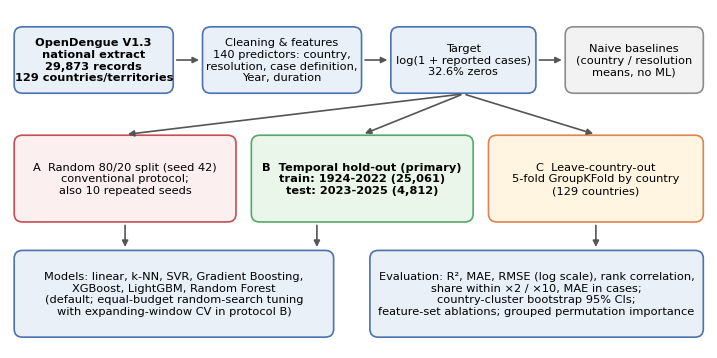

Figure 2 - Data overview (cases, records, countries per year)


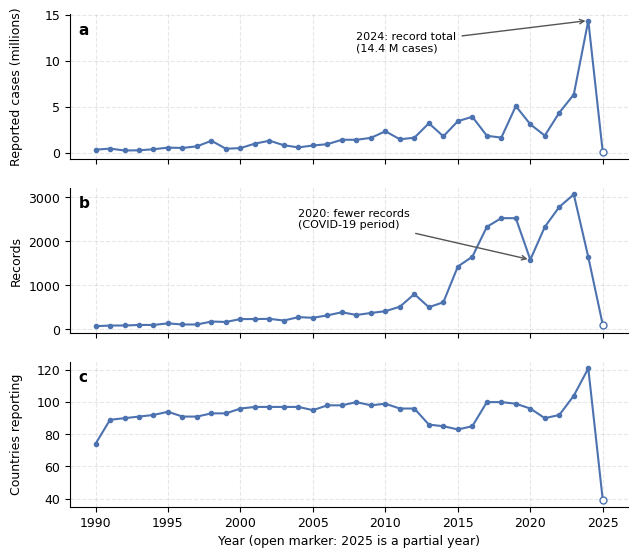

Figure 3 - Distribution of the target


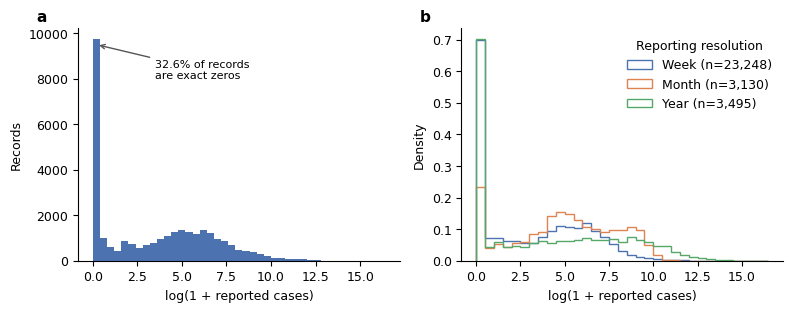

Figure 4 - Three evaluation protocols (R2 with 95% CI)


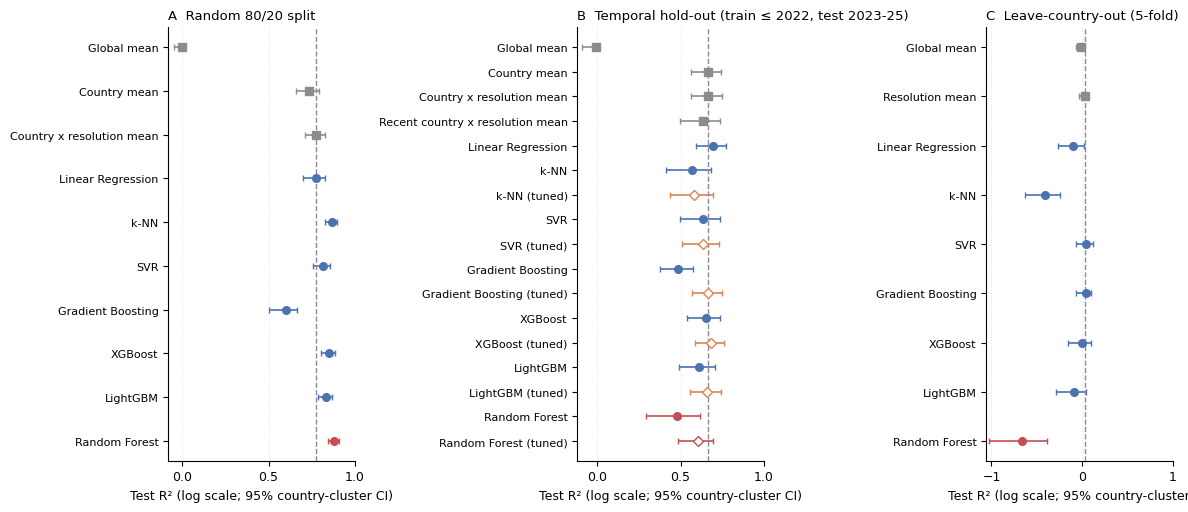

Figure 5 - Feature-set ablation


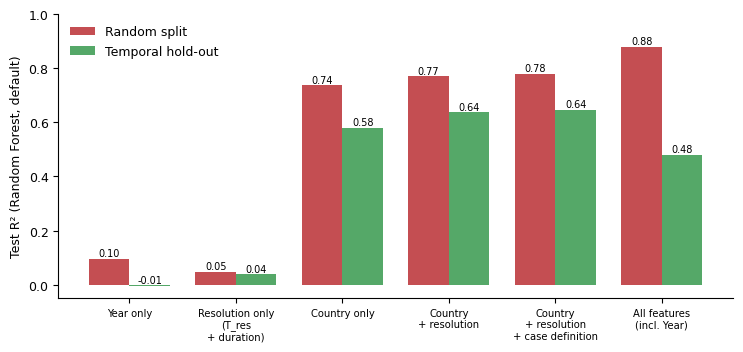

Figure 6 - Actual vs predicted (temporal hold-out)


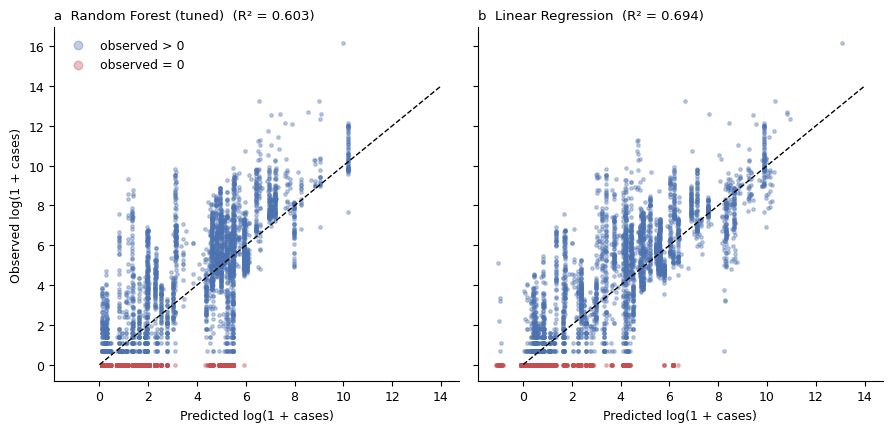

Figure 7 - Residual analysis


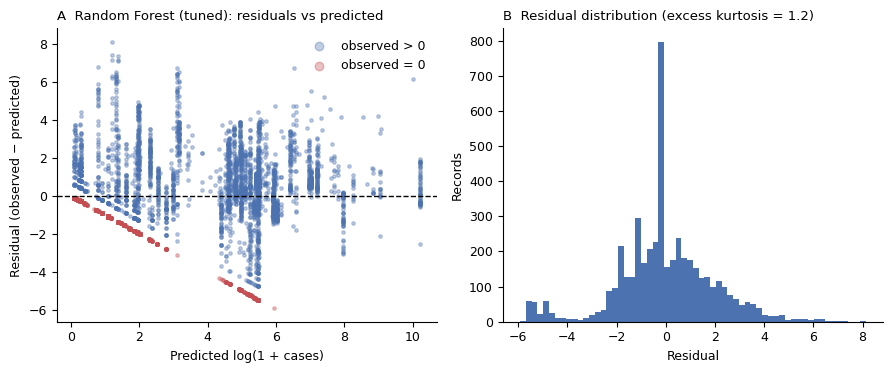

{'excess_kurtosis': 1.2050414595092862, 'mean_resid': -0.02740499990214363, 'sd_resid': 2.024524849962124, 'share_abs_gt2': 0.2520781379883624, 'resid_min': -5.925244017943799, 'resid_max': 8.129803156426192}
Figure 8 - Feature importance


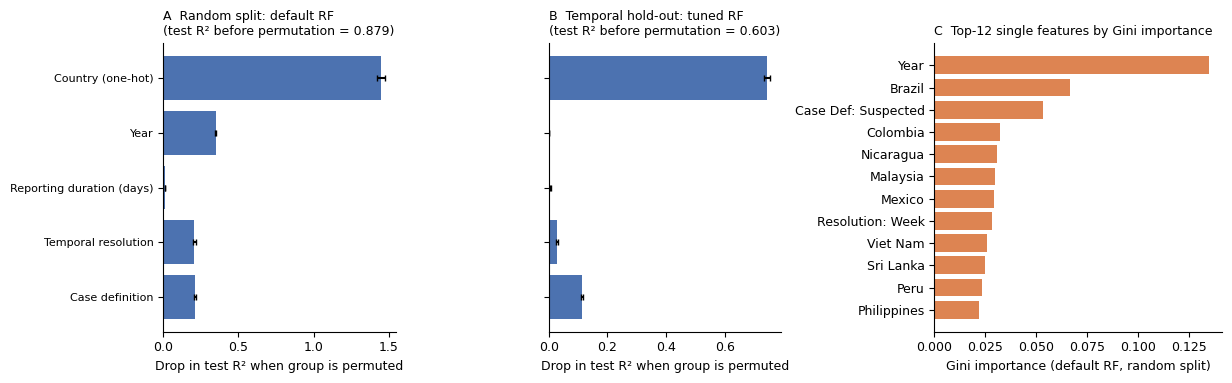

In [67]:
print("Figure 1 - Study design");                                      fig1()
print("Figure 2 - Data overview (cases, records, countries per year)");  fig2()
print("Figure 3 - Distribution of the target");                          fig3()
print("Figure 4 - Three evaluation protocols (R2 with 95% CI)");         fig4()
print("Figure 5 - Feature-set ablation");                                fig5()
print("Figure 6 - Actual vs predicted (temporal hold-out)");             fig6()
print("Figure 7 - Residual analysis");  res7 = fig7()
json.dump(res7, open(f"{OUT}/resid_stats.json", "w")); print(res7)
print("Figure 8 - Feature importance");                                  fig8()


## 14. Every number and table used in the paper, Sections 1-4 (paper_data.json)

In [68]:
import json, sys
import numpy as np, pandas as pd
import sklearn, xgboost, lightgbm, scipy

X, y, raw = load()
rnd, tmp, tun, loco = loadp("random.pkl"), loadp("temporal.pkl"), loadp("tune.pkl"), loadp("loco.pkl")
diag, imp_r, ext = loadp("diag.pkl"), loadp("importance_random.pkl"), loadp("extreme.pkl")
seeds, abl, roll = pd.read_csv(f"{OUT}/seeds.csv"), pd.read_csv(f"{OUT}/ablation.csv"), pd.read_csv(f"{OUT}/rolling.csv")
repro = json.load(open(f"{OUT}/repro.json")); rs = json.load(open(f"{OUT}/resid_stats.json"))
f2 = lambda v: f"{v:.2f}".replace("-0.00", "0.00"); f3 = lambda v: f"{v:.3f}".replace("-0.000", "0.000"); f4 = lambda v: f"{v:.4f}"
ci = lambda lo, hi, f=f3: f"[{f(lo)}, {f(hi)}]"
N, T = {}, {}

# ---------------- dataset ----------------
d = raw["dengue_total"]
N.update(n_rec=f"{len(raw):,}", n_ctry=str(raw.adm_0_name.nunique()), n_src=f"{raw.UUID.nunique():,}",
         y_min=str(raw.Year.min()), y_max=str(raw.Year.max()), n_pred=str(X.shape[1]),
         zero_share=f"{(d==0).mean()*100:.1f}", n_zero=f"{int((d==0).sum()):,}",
         med=f"{d.median():.0f}", mean=f"{d.mean():,.1f}", sd=f"{d.std():,.1f}", maxv=f"{d.max():,.0f}", total_cases=f"{d.sum()/1e6:.1f}",
         ylog_mean=f2(y.mean()), ylog_sd=f2(y.std()), ylog_max=f2(y.max()),
         share_week=f"{(raw.T_res=='Week').mean()*100:.1f}", share_month=f"{(raw.T_res=='Month').mean()*100:.1f}", share_year=f"{(raw.T_res=='Year').mean()*100:.1f}",
         n_week=f"{(raw.T_res=='Week').sum():,}", n_month=f"{(raw.T_res=='Month').sum():,}", n_yearres=f"{(raw.T_res=='Year').sum():,}",
         share_post2000=f"{(raw.Year>=2000).mean()*100:.1f}", share_post2014=f"{(raw.Year>=2014).mean()*100:.1f}",
         zero_week=f"{d[raw.T_res=='Week'].eq(0).mean()*100:.1f}", zero_month=f"{d[raw.T_res=='Month'].eq(0).mean()*100:.1f}", zero_yr=f"{d[raw.T_res=='Year'].eq(0).mean()*100:.1f}",
         n_casedef=str(raw.case_definition_standardised.nunique()))
g = raw.groupby("Year").agg(cases=("dengue_total", "sum"), records=("dengue_total", "size"), ctry=("adm_0_name", "nunique"))
for yv in (2019, 2020, 2023, 2024, 2025):
    N[f"cases_{yv}"] = f"{g.loc[yv,'cases']/1e6:.1f}"; N[f"rec_{yv}"] = f"{int(g.loc[yv,'records']):,}"; N[f"ctry_{yv}"] = str(int(g.loc[yv, 'ctry']))
N["cases_2024_full"] = f"{g.loc[2024,'cases']:,.0f}"
N["n_train_B"], N["n_test_B"] = f"{len(tmp['tr']):,}", f"{len(tmp['te']):,}"
N["n_train_A"], N["n_test_A"] = f"{len(rnd['tr']):,}", f"{len(rnd['te']):,}"
c = diag["counts"]
N.update(n_unseen_rows=f"{c['n_unseen_rows']:,}", n_unseen_ctry=str(c["n_unseen_countries"]), unseen_pct=f"{c['n_unseen_rows']/c['n_test']*100:.1f}",
         zero_test=f"{c['zero_share_test']*100:.1f}", zero_2023=f"{c['zero_share_by_year'][2023]*100:.0f}", zero_2024=f"{c['zero_share_by_year'][2024]*100:.0f}", zero_2025=f"{c['zero_share_by_year'][2025]*100:.0f}")
lk_r, lk_t = diag["leak_random"], diag["leak_temporal"]
N.update(leak_cy_A=f"{lk_r['country_year_in_train']*100:.1f}", leak_cy_B=f"{lk_t['country_year_in_train']*100:.1f}",
         leak_wk_A=f"{lk_r['weekly_adjacent_week_in_train']*100:.1f}", leak_wk_B=f"{lk_t['weekly_adjacent_week_in_train']*100:.1f}")
N.update(py="3.12", sk=sklearn.__version__, xgb=xgboost.__version__, lgb=lightgbm.__version__, pd=pd.__version__, npv=np.__version__)

# ---------------- reproduction ----------------
order_ml = ["Linear Regression", "SVR", "k-NN", "Gradient Boosting", "XGBoost", "LightGBM", "Random Forest"]
orig = {"Linear Regression": 0.7744, "SVR": 0.8119, "k-NN": 0.8698, "Gradient Boosting": 0.6010, "XGBoost": 0.8513, "LightGBM": 0.8340, "Random Forest": 0.8791}
T["repro"] = [[m, f4(orig[m]), f4(repro[m]["R2"]), f4(repro[m]["MAE"]), f4(repro[m]["MSE"])] for m in order_ml]
N["repro_maxdiff"] = f"{max(abs(orig[m]-repro[m]['R2']) for m in order_ml):.4f}"
N["repro_n_pred"] = str(repro["n_predictors"])
for m, k in [("Gradient Boosting", "gb"), ("XGBoost", "xgb_"), ("LightGBM", "lgbm")]:
    N[f"repro_mae_{k}"], N[f"repro_mse_{k}"] = f4(repro[m]["MAE"]), f4(repro[m]["MSE"])

# ---------------- main results ----------------
bR, bT, bL = diag["boot_random"], diag["boot_temporal"], diag["boot_loco"]
A, B, L = rnd["metrics"], {**tmp["metrics"], **{f"{k} (tuned)": v for k, v in tun["metrics"].items()}}, loco["metrics"]
def cell(met, boot, k): return f"{f3(met[k]['R2'])} {ci(boot[0][k]['R2_lo'], boot[0][k]['R2_hi'])}", f"{met[k]['MAE']:.3f}"
base_rows = [("Global mean", "Global mean"), ("Country mean", "Country mean"), ("Country × resolution mean", "Country x resolution mean")]
rows = []
for lab, k in base_rows:
    a, b_ = cell(A, bR, k), cell(B, bT, k)
    rows.append([lab + " (baseline)", a[0], a[1], b_[0], b_[1], cell(L, bL, k)[0] if k in L else "n/a", cell(L, bL, k)[1] if k in L else "n/a"])
rows.append(["Recent (2021-22) country × resolution mean (baseline)", "n/a", "n/a", *cell(B, bT, "Recent country x resolution mean"), "n/a", "n/a"])
rows.append(["Resolution mean (baseline)", "n/a", "n/a", "n/a", "n/a", *cell(L, bL, "Resolution mean")])
for m in order_ml:
    a, b_, l_ = cell(A, bR, m), cell(B, bT, m), cell(L, bL, m)
    rows.append([m, a[0], a[1], b_[0], b_[1], l_[0], l_[1]])
T["main"] = rows
rows = []
for m in ["Linear Regression", "SVR", "k-NN", "Gradient Boosting", "XGBoost", "LightGBM", "Random Forest"]:
    if f"{m} (tuned)" in B:
        d0, d1 = cell(B, bT, m), cell(B, bT, f"{m} (tuned)")
        rows.append([m, d0[0], d1[0], f3(B[f"{m} (tuned)"]["R2"] - B[m]["R2"]), f3(tun["cv"][m])])
T["tuned"] = rows
T["best_params"] = [[m, ", ".join(f"{k}={v}" for k, v in p.items())] for m, p in tun["best"].items()]
N["rf_tuned_secs"] = f"{tun['seconds']['Random Forest']/60:.0f}"

# scalar shortcuts
for tag, met, boot in [("A", A, bR), ("B", B, bT), ("C", L, bL)]:
    for k, key in [("Random Forest", "rf"), ("Linear Regression", "lr"), ("Country x resolution mean", "cxr"), ("Country mean", "cm"), ("XGBoost", "xg"), ("LightGBM", "lg"), ("k-NN", "knn"), ("SVR", "svr"), ("Gradient Boosting", "gb"),
                   ("Global mean", "gm"), ("Resolution mean", "rm"), ("Recent country x resolution mean", "rec"), ("Random Forest (tuned)", "rft"), ("XGBoost (tuned)", "xgt"), ("LightGBM (tuned)", "lgt"),
                   ("Linear Regression (tuned)", "lrt"), ("k-NN (tuned)", "knnt"), ("SVR (tuned)", "svrt"), ("Gradient Boosting (tuned)", "gbt")]:
        if k in met:
            N[f"{key}_{tag}"] = f3(met[k]["R2"]); N[f"{key}_{tag}_mae"] = f3(met[k]["MAE"])
            if k in boot[0]: N[f"{key}_{tag}_ci"] = ci(boot[0][k]["R2_lo"], boot[0][k]["R2_hi"])
for tag, boot in [("A", bR), ("B", bT), ("C", bL)]:
    for pair, d_ in boot[1].items():
        key = pair.replace(" minus ", "_m_").replace(" ", "").replace("(", "").replace(")", "").replace("×", "x")
        N[f"d_{tag}_{key}"] = f"{d_['dR2_lo']:+.3f} to {d_['dR2_hi']:+.3f}"
        N[f"dm_{tag}_{key}"] = f"{d_['dMAE_lo']:+.3f} to {d_['dMAE_hi']:+.3f}"
N["rf_A_minus_cxr"] = f3(A["Random Forest"]["R2"] - A["Country x resolution mean"]["R2"])
N["rf_B_minus_cxr"] = f3(B["Random Forest"]["R2"] - B["Country x resolution mean"]["R2"])
N["rft_B_minus_cxr"] = f3(B["Random Forest (tuned)"]["R2"] - B["Country x resolution mean"]["R2"])
N["lr_B_minus_cxr"] = f3(B["Linear Regression"]["R2"] - B["Country x resolution mean"]["R2"])
N["best_B_name"] = max([k for k in B if "mean" not in k], key=lambda k: B[k]["R2"])
N["best_B_r2"] = f3(B[N["best_B_name"]]["R2"]); N["best_B_ci"] = ci(bT[0][N["best_B_name"]]["R2_lo"], bT[0][N["best_B_name"]]["R2_hi"])
N["best_cv_name"] = max(tun["cv"], key=tun["cv"].get); N["best_cv_val"] = f3(tun["cv"][N["best_cv_name"]])

# ---------------- seeds ----------------
sg = seeds.groupby("model")[["R2", "MAE"]].agg(["mean", "std"])
for m, k in [("Random Forest", "rf"), ("Linear Regression", "lr"), ("LightGBM", "lg"), ("Country x resolution mean", "cxr"), ("Country mean", "cm")]:
    N[f"seed_{k}_m"], N[f"seed_{k}_sd"] = f4(sg.loc[m, ("R2", "mean")]), f4(sg.loc[m, ("R2", "std")])
    N[f"seed_{k}_min"], N[f"seed_{k}_max"] = f3(seeds[seeds.model == m].R2.min()), f3(seeds[seeds.model == m].R2.max())
T["seeds"] = [[m, f"{sg.loc[m, ('R2','mean')]:.4f}", f"{sg.loc[m, ('R2','std')]:.4f}", f"{seeds[seeds.model==m].R2.min():.3f}–{seeds[seeds.model==m].R2.max():.3f}", f"{sg.loc[m, ('MAE','mean')]:.3f}"]
              for m in ["Country mean", "Country x resolution mean", "Linear Regression", "LightGBM", "Random Forest"]]
# original-run tuned RF gains (random split) vs seed SD
N["orig_gain_grid"], N["orig_gain_rand"] = "0.0011", "0.0022"

# ---------------- ablation ----------------
feats = list(dict.fromkeys(abl["features"]))
T["ablation"] = [[f, f3(abl[(abl.features == f) & (abl.protocol == "Random split")].R2.iloc[0]), f3(abl[(abl.features == f) & (abl.protocol == "Random split")].MAE.iloc[0]),
                  f3(abl[(abl.features == f) & (abl.protocol == "Temporal hold-out")].R2.iloc[0]), f3(abl[(abl.features == f) & (abl.protocol == "Temporal hold-out")].MAE.iloc[0])] for f in feats]
ab = lambda f, p: abl[(abl.features == f) & (abl.protocol == p)].R2.iloc[0]
N.update(abl_ctry_A=f3(ab("Country only", "Random split")), abl_ctry_B=f3(ab("Country only", "Temporal hold-out")),
         abl_cr_A=f3(ab("Country + resolution", "Random split")), abl_cr_B=f3(ab("Country + resolution", "Temporal hold-out")),
         abl_crc_A=f3(ab("Country + resolution + case definition", "Random split")), abl_crc_B=f3(ab("Country + resolution + case definition", "Temporal hold-out")),
         abl_all_A=f3(ab("All features (incl. Year)", "Random split")), abl_all_B=f3(ab("All features (incl. Year)", "Temporal hold-out")),
         abl_year_A=f3(ab("Year only", "Random split")), abl_year_B=f3(ab("Year only", "Temporal hold-out")),
         abl_res_A=f3(ab("Resolution only (T_res + duration)", "Random split")), abl_res_B=f3(ab("Resolution only (T_res + duration)", "Temporal hold-out")))
N["year_gain_A"] = f3(ab("All features (incl. Year)", "Random split") - ab("Country + resolution + case definition", "Random split"))
N["year_loss_B"] = f3(ab("Country + resolution + case definition", "Temporal hold-out") - ab("All features (incl. Year)", "Temporal hold-out"))
N["ctry_share_A"] = f"{ab('Country only','Random split')/ab('All features (incl. Year)','Random split')*100:.0f}"

# ---------------- rolling origin ----------------
piv = roll.pivot(index="model", columns="test_year", values="R2")
mods = ["Country mean", "Country x resolution mean", "Linear Regression", "k-NN", "XGBoost", "LightGBM", "LightGBM (no Year)", "Random Forest", "Random Forest (no Year)"]
T["rolling_cols"] = [str(c) for c in piv.columns]
T["rolling"] = [[m] + [f"{piv.loc[m, c]:.2f}" for c in piv.columns] + [f"{piv.loc[m].mean():.3f}"] for m in mods]
for m, k in [("Random Forest", "rf"), ("Random Forest (no Year)", "rfny"), ("Linear Regression", "lr"), ("Country x resolution mean", "cxr"), ("LightGBM (no Year)", "lgny"), ("Country mean", "cm"), ("XGBoost", "xg")]:
    N[f"roll_{k}"] = f3(piv.loc[m].mean())
N["roll_rf_below_cxr_years"] = str(int((piv.loc["Random Forest"] < piv.loc["Country x resolution mean"]).sum())); N["roll_n_years"] = str(piv.shape[1])
N["roll_lr_above_cxr_years"] = str(int((piv.loc["Linear Regression"] > piv.loc["Country x resolution mean"]).sum()))
N["roll_rf_min"], N["roll_rf_max"] = f2(piv.loc["Random Forest"].min()), f2(piv.loc["Random Forest"].max())
N["roll_y_first"], N["roll_y_last"] = str(piv.columns.min()), str(piv.columns.max())

# ---------------- extended metrics (temporal) ----------------
ext_models = ["Country x resolution mean", "Linear Regression", "XGBoost", "Random Forest", "Random Forest (tuned)"]
T["extended"] = [[m, f3(B[m]["R2"]), f3(B[m]["MAE"]), f3(B[m]["RMSE"]), f3(B[m]["Spearman"]), f"{B[m]['within_x2']*100:.1f}", f"{B[m]['within_x10']*100:.1f}", f"{B[m]['MAE_cases']:,.0f}"] for m in ext_models]
N["mae_cases_gm"] = f"{B['Global mean']['MAE_cases']:,.0f}"; N["mae_cases_rft"] = f"{B['Random Forest (tuned)']['MAE_cases']:,.0f}"; N["mae_cases_lr"] = f"{B['Linear Regression']['MAE_cases']:,.0f}"
N["w2_rft"] = f"{B['Random Forest (tuned)']['within_x2']*100:.0f}"; N["w2_lr"] = f"{B['Linear Regression']['within_x2']*100:.0f}"; N["w10_lr"] = f"{B['Linear Regression']['within_x10']*100:.0f}"
N["w10_rft"] = f"{B['Random Forest (tuned)']['within_x10']*100:.0f}"
bd = diag["breakdown"]
T["breakdown"] = [[m, f3(bd[m]["R2_seen"]), f3(bd[m]["MAE_seen"]), f3(bd[m]["MAE_unseen"]), f3(bd[m]["MAE_zero"]), f3(bd[m]["MAE_positive"]), f2(bd[m]["mean_pred_zero"])] for m in ["Country x resolution mean", "Linear Regression", "Random Forest (tuned)"]]
N.update(mae_zero_rft=f3(bd["Random Forest (tuned)"]["MAE_zero"]), mae_pos_rft=f3(bd["Random Forest (tuned)"]["MAE_positive"]), meanpred_zero_rft=f2(bd["Random Forest (tuned)"]["mean_pred_zero"]),
         mae_zero_lr=f3(bd["Linear Regression"]["MAE_zero"]), mae_pos_lr=f3(bd["Linear Regression"]["MAE_positive"]), meanpred_zero_lr=f2(bd["Linear Regression"]["mean_pred_zero"]),
         r2_seen_rft=f3(bd["Random Forest (tuned)"]["R2_seen"]), r2_seen_lr=f3(bd["Linear Regression"]["R2_seen"]), r2_seen_cxr=f3(bd["Country x resolution mean"]["R2_seen"]),
         mae_unseen_rft=f3(bd["Random Forest (tuned)"]["MAE_unseen"]), mae_unseen_lr=f3(bd["Linear Regression"]["MAE_unseen"]), mae_seen_rft=f3(bd["Random Forest (tuned)"]["MAE_seen"]))
N.update({f"resid_{k}": (f"{v:.2f}" if abs(v) < 100 else f"{v:.0f}") for k, v in rs.items()}); N["resid_share_gt2"] = f"{rs['share_abs_gt2']*100:.1f}"

# ---------------- large outbreaks ----------------
T["extreme"] = []
for thr in (">=1000", ">=10000", ">=100000"):
    e = ext[thr]
    for m in ["Random Forest (tuned)", "Linear Regression", "Country x resolution mean"]:
        T["extreme"].append([f"≥ {int(thr[2:]):,} cases (n = {e['n']})", m, f"{e[m]['median_pred_over_obs']:.2f}", f"{e[m]['share_within_x2']*100:.0f}", f"{e[m]['share_underpredicted']*100:.0f}"])
N.update(ext10k_n=str(ext[">=10000"]["n"]), ext100k_n=str(ext[">=100000"]["n"]),
         ext10k_med_rft=f"{ext['>=10000']['Random Forest (tuned)']['median_pred_over_obs']:.2f}", ext10k_med_lr=f"{ext['>=10000']['Linear Regression']['median_pred_over_obs']:.2f}",
         ext10k_w2_rft=f"{ext['>=10000']['Random Forest (tuned)']['share_within_x2']*100:.0f}", ext10k_w2_lr=f"{ext['>=10000']['Linear Regression']['share_within_x2']*100:.0f}",
         ext10k_under_rft=f"{ext['>=10000']['Random Forest (tuned)']['share_underpredicted']*100:.0f}", ext10k_under_lr=f"{ext['>=10000']['Linear Regression']['share_underpredicted']*100:.0f}",
         ext100k_med_rft=f"{ext['>=100000']['Random Forest (tuned)']['median_pred_over_obs']:.2f}", ext100k_med_lr=f"{ext['>=100000']['Linear Regression']['median_pred_over_obs']:.2f}",
         ext100k_w2_lr=f"{ext['>=100000']['Linear Regression']['share_within_x2']*100:.0f}", ext100k_w2_rft=f"{ext['>=100000']['Random Forest (tuned)']['share_within_x2']*100:.0f}",
         ext100k_under_rft=f"{ext['>=100000']['Random Forest (tuned)']['share_underpredicted']*100:.0f}", ext100k_under_lr=f"{ext['>=100000']['Linear Regression']['share_underpredicted']*100:.0f}")

# ---------------- importance ----------------
pr, pt = imp_r["perm"], tun["perm_tuned_rf_temporal"]["imp"]
T["perm"] = [[g, f"{pr[g][0]:.3f} ± {pr[g][1]:.3f}", f"{pt[g][0]:.3f} ± {pt[g][1]:.3f}"] for g in pr]
N.update(perm_ctry_A=f3(pr["Country (one-hot)"][0]), perm_year_A=f3(pr["Year"][0]), perm_ctry_B=f3(pt["Country (one-hot)"][0]), perm_year_B=f3(pt["Year"][0]),
         perm_base_A=f3(imp_r["base_R2"]), perm_base_B=f3(tun["perm_tuned_rf_temporal"]["base_R2"]),
         gini_ctry=f"{imp_r['gini_group']['Country (one-hot)']*100:.1f}", gini_year=f"{imp_r['gini_group']['Year']*100:.1f}", gini_case=f"{imp_r['gini_group']['Case definition']*100:.1f}",
         gini_res=f"{imp_r['gini_group']['Temporal resolution']*100:.1f}", gini_dur=f"{imp_r['gini_group']['Reporting duration (days)']*100:.1f}")
top = imp_r["gini_top20"]; names = [t[0] for t in top]
N["gini_top5"] = ", ".join(f"{t[0].replace('adm_0_name_','').replace('case_definition_standardised_','case definition: ').replace('_',' ').title() if t[0]!='Year' else 'Year'} ({t[1]:.3f})" for t in top[:5])
N["gini_year_v"] = f3(dict(top)["Year"])
N["gini_top20_has_bermuda"] = str("adm_0_name_BERMUDA" in names or "adm_0_name_VIRGIN_ISLANDS_US" in names)
N["gini_bermuda_rank"] = str(names.index("adm_0_name_BERMUDA") + 1) if "adm_0_name_BERMUDA" in names else "n/a"
N["gini_vi_rank"] = str(names.index("adm_0_name_VIRGIN_ISLANDS_US") + 1) if "adm_0_name_VIRGIN_ISLANDS_US" in names else "n/a"
gt = tun["gini_tuned_rf"]; N["gini_tuned_year"] = f3(gt["Year"])


ep = json.load(open(f"{OUT}/extra_pairs.json"))
for k, nm in [("XGBoost (tuned) minus cxr", "xgt"), ("Gradient Boosting (tuned) minus cxr", "gbt"), ("LightGBM (tuned) minus cxr", "lgt"), ("SVR (tuned) minus cxr", "svrt")]:
    N[f"dB_{nm}_cxr"] = f"{ep[k]['dR2_lo']:+.3f} to {ep[k]['dR2_hi']:+.3f}"
N["xgt_minus_cxr"] = f3(B["XGBoost (tuned)"]["R2"] - B["Country x resolution mean"]["R2"])
N["loco_max_ml"] = f3(max(L[m]["R2"] for m in order_ml))
N["rec_1990"] = f"{int(g.loc[1990,'records'])}"
N["ctry_rec_2023_max"] = str(int(g["ctry"].loc[2015:2024].max()))
N["zero_ext"] = ""
json.dump({"N": N, "T": T}, open(f"{OUT}/paper_data.json", "w"), indent=1, default=str)
print(len(N), "numbers;", list(T), "tables"); print("best temporal:", N["best_B_name"], N["best_B_r2"], "| best CV:", N["best_cv_name"], N["best_cv_val"])

# ---------------- Protocol A companion: 5-fold cross-validation ----------------
kf = loadp("kfold.pkl")
T["kfold"] = [[m, f3(kf[m]["R2_mean"]), f3(kf[m]["R2_sd"]), f3(kf[m]["MAE_mean"]), f3(A[m]["R2"]) if m in A else f3(A.get("Global mean", {"R2": 0})["R2"])]
             for m in ["Country mean", "Country x resolution mean", "Linear Regression", "SVR", "k-NN", "Gradient Boosting", "XGBoost", "LightGBM", "Random Forest"]]
for m, k in [("Random Forest", "rf"), ("k-NN", "knn"), ("SVR", "svr"), ("Linear Regression", "lr"), ("Country x resolution mean", "cxr"), ("XGBoost", "xg"), ("LightGBM", "lg"), ("Gradient Boosting", "gb"), ("Country mean", "cm")]:
    N[f"kf_{k}_mean"] = f3(kf[m]["R2_mean"]); N[f"kf_{k}_sd"] = f3(kf[m]["R2_sd"]); N[f"kf_{k}_mae"] = f3(kf[m]["MAE_mean"])
N["kf_knn_single"] = f3(A["k-NN"]["R2"]); N["kf_knn_gap"] = f3(A["k-NN"]["R2"] - kf["k-NN"]["R2_mean"])
N["kf_rf_single"] = f3(A["Random Forest"]["R2"]); N["kf_rf_gap"] = f3(A["Random Forest"]["R2"] - kf["Random Forest"]["R2_mean"])
N["kf_max_gap_model"] = max(["Linear Regression", "SVR", "k-NN", "Gradient Boosting", "XGBoost", "LightGBM", "Random Forest"], key=lambda m: abs(A[m]["R2"] - kf[m]["R2_mean"]))
N["kf_max_gap"] = f3(abs(A[N["kf_max_gap_model"]]["R2"] - kf[N["kf_max_gap_model"]]["R2_mean"]))
json.dump({"N": N, "T": T}, open(f"{OUT}/paper_data.json", "w"), indent=1, default=str)
print("kfold added:", N["kf_knn_mean"], "vs single", N["kf_knn_single"])

336 numbers; ['repro', 'main', 'tuned', 'best_params', 'seeds', 'ablation', 'rolling_cols', 'rolling', 'extended', 'breakdown', 'extreme', 'perm'] tables
best temporal: Linear Regression 0.694 | best CV: XGBoost 0.763
kfold added: 0.813 vs single 0.869


## 15. Section 5 — A genuine forecasting model: setup

This part builds a second, independent analysis: forecasting *future* dengue case counts of a
weekly series from its own recent history (lagged case counts), rather than predicting a
reporting period's level from country/year/resolution as in Sections 1-4 above. It needs:

* the OpenDengue national extract (already loaded above), for the ~100 weekly national series, and
* the OpenDengue V1.3 **spatial** extract (Admin1 sub-national data), used only for the
  cross-country/cross-scale transfer test in Section 5.6. It is read from `SPATIAL_RAW_CSV` (set in the first code cell).
  The weekly Admin1 rows are extracted once and cached in `SPATIAL_PKL`.

In [73]:
import sys, time, json, warnings

import numpy as np, pandas as pd

from sklearn.linear_model import Ridge

from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import GroupKFold

from sklearn.metrics import roc_auc_score, r2_score

import lightgbm as lgb

warnings.filterwarnings("ignore")

T0 = time.time()

def log(*a): print(f"[{time.time()-T0:6.0f}s]", *a, flush=True)

H_LIST = [1, 2, 4, 8, 12]

EPOCH = pd.Timestamp("1900-01-07")           # a Sunday; OpenDengue epi-weeks start on Sunday

CUT = pd.Timestamp("2023-01-01")             # first test target date (temporal hold-out)

LAGS = [0, 1, 2, 3, 4, 8, 12, 26, 52]

WINS = [4, 8, 13, 26, 52]

SPLIT_DATA = os.environ.get("SPATIAL_PKL", "admin1_weekly.pkl")   # produced by prepare_admin1()

def load_weekly_national():
    df = pd.read_csv(DATA)
    w = df[df.T_res == "Week"].copy()
    w["cd"] = w["case_definition_standardised"].str.strip().str.capitalize()
    w["start"] = _dates(w["calendar_start_date"])
    w["cases"] = w["dengue_total"].astype(float)
    w["unit"] = w["adm_0_name"]
    return w[["adm_0_name", "unit", "cd", "start", "cases"]]

def prepare_admin1(spatial_csv, out_pkl):
    """Extract weekly Admin1 rows from the OpenDengue spatial extract (run once)."""
    cols = ["adm_0_name", "adm_1_name", "S_res", "T_res", "calendar_start_date", "case_definition_standardised", "dengue_total"]
    parts = [c[(c.S_res == "Admin1") & (c.T_res == "Week")] for c in pd.read_csv(spatial_csv, usecols=cols, chunksize=300000, low_memory=False)]
    a = pd.concat(parts); a.to_pickle(out_pkl); return a

def load_weekly_admin1():
    a = pd.read_pickle(SPLIT_DATA)
    a = a.copy()
    a["cd"] = a["case_definition_standardised"].str.strip().str.capitalize()
    a["start"] = _dates(a["calendar_start_date"]); a["cases"] = a["dengue_total"].astype(float)
    a["unit"] = a["adm_0_name"] + "|" + a["adm_1_name"].astype(str)
    return a[["adm_0_name", "unit", "cd", "start", "cases"]]

def series_frame(g, H):
    k = ((g["start"] - EPOCH).dt.days // 7).to_numpy()
    kmin, kmax = k.min(), k.max()
    arr = np.full(kmax - kmin + 1, np.nan); arr[k - kmin] = np.log1p(g["cases"].to_numpy())
    s = pd.Series(arr); d = {}
    for L in LAGS: d[f"lag{L}"] = s.shift(L)
    for W in WINS: d[f"mean{W}"] = s.rolling(W, min_periods=max(2, W // 4)).mean()
    d["max13"] = s.rolling(13, min_periods=2).max(); d["std8"] = s.rolling(8, min_periods=3).std()
    d["zero13"] = (s == 0).astype(float).where(s.notna()).rolling(13, min_periods=3).mean()
    d["d1"] = s - s.shift(1); d["d4"] = s - s.shift(4); d["accel"] = (s - s.shift(2)) - (s.shift(2) - s.shift(4))
    d["exp_mean"] = s.expanding(min_periods=4).mean(); d["exp_max"] = s.expanding(min_periods=4).max()
    d["hist_len"] = s.notna().cumsum().astype(float); d["n_obs13"] = s.notna().rolling(13, min_periods=1).sum()
    for h in H:
        d[f"tgt{h}"] = s.shift(-h); d[f"sn{h}"] = s.shift(52 - h); d[f"sd{h}"] = s.shift(52 - h) - s.shift(52)
    f = pd.DataFrame(d); f["k"] = np.arange(kmin, kmax + 1)
    f["date"] = EPOCH + pd.to_timedelta(f["k"] * 7, unit="D")
    return f[s.notna().to_numpy()]                                   # origins = observed weeks

def build(w, H=H_LIST):
    out = []
    for (u, cd), g in w.groupby(["unit", "cd"]):
        f = series_frame(g, H); f["unit"] = u; f["cd"] = cd; f["adm_0_name"] = g["adm_0_name"].iloc[0]; out.append(f)
    F = pd.concat(out, ignore_index=True)
    F["woy"] = F["date"].dt.isocalendar().week.astype(float).to_numpy()
    F["year"] = F["date"].dt.year.astype(float)
    return F

FILL_Y0 = [f"lag{L}" for L in LAGS[1:]] + [f"mean{W}" for W in WINS] + ["max13", "exp_mean", "exp_max"]

SHORT = ["lag0", "lag1", "lag2", "lag3", "lag4", "d1", "d4", "accel", "mean4"]

LONG = ["lag8", "lag12", "lag26", "lag52", "mean8", "mean13", "mean26", "mean52", "max13", "std8", "zero13"]

HIST = ["exp_mean", "exp_max", "hist_len", "n_obs13"]

def feature_sets(h):
    seas = [f"sn{h}", f"sd{h}"]
    return {"Persistence-equivalent (lag0 only)": ["lag0"],
            "Short lags": SHORT,
            "+ long windows": SHORT + LONG,
            "+ seasonal (same week last year)": SHORT + LONG + seas,
            "All lag features": SHORT + LONG + seas + HIST + ["case_Suspected", "case_Confirmed", "case_Total"]}

def prep_xy(F, h, feats):
    """Return X (raw, with NaN), X filled, delta target, meta for horizon h."""
    d = F.copy()
    for c in ("Suspected", "Confirmed", "Total"): d[f"case_{c}"] = (d["cd"] == c).astype(float)
    ok = d["lag0"].notna() & d[f"tgt{h}"].notna() & (d["hist_len"] >= 8)
    d = d[ok].copy(); d["tdate"] = d["date"] + pd.to_timedelta(7 * h, unit="D")
    X = d[feats].astype(float)
    Xf = X.copy()
    for c in feats:
        if c in FILL_Y0 or c == f"sn{h}": Xf[c] = Xf[c].fillna(d["lag0"])
        else: Xf[c] = Xf[c].fillna(0.0)
    if f"sn{h}" in feats or "lag52" in feats:
        Xf["has52"] = d["lag52"].notna().astype(float).to_numpy()
    y = d[f"tgt{h}"].to_numpy(); y0 = d["lag0"].to_numpy()
    return d, X, Xf, y - y0, y, y0

def baselines(d, h):
    y0 = d["lag0"].to_numpy()
    return {"Persistence": y0, "4-week mean": d["mean4"].fillna(d["lag0"]).to_numpy(),
            "Seasonal naive (52 wk)": d[f"sn{h}"].fillna(d["lag0"]).to_numpy(),
            "Expanding mean": d["exp_mean"].fillna(d["lag0"]).to_numpy()}

LGB_DEFAULT = dict(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
                   colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1, n_jobs=NJOBS)

def fit_models(Xtr, Xftr, dtr, Xte, Xfte, which=("Ridge", "LightGBM", "Random Forest"), lgb_params=None):
    """Train on delta target; return dict of test predictions of delta."""
    P = {}
    if "Ridge" in which:
        mu, sd = Xftr.mean(), Xftr.std().replace(0, 1)
        m = Ridge(alpha=1.0).fit((Xftr - mu) / sd, dtr["y"]); P["Ridge (lags)"] = m.predict((Xfte - mu) / sd)
    if "LightGBM" in which:
        m = lgb.LGBMRegressor(**(lgb_params or LGB_DEFAULT)).fit(Xtr, dtr["y"]); P["LightGBM (lags)"] = m.predict(Xte)
    if "Random Forest" in which:
        m = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=NJOBS).fit(Xftr, dtr["y"])
        P["Random Forest (lags)"] = m.predict(Xfte)
    return P

def split_temporal(d, cut=CUT, last=None):
    tr = (d["tdate"] < cut).to_numpy()
    te = (d["tdate"] >= cut).to_numpy() if last is None else ((d["tdate"] >= cut) & (d["tdate"] < last)).to_numpy()
    return tr, te

def fc_metrics(y, p, y0):
    e = y - p; e0 = y - y0
    return {"R2": float(r2_score(y, p)), "MAE": float(np.abs(e).mean()), "RMSE": float(np.sqrt((e ** 2).mean())),
            "skill_MAE": float(1 - np.abs(e).mean() / np.abs(e0).mean()), "skill_RMSE": float(1 - np.sqrt((e ** 2).mean()) / np.sqrt((e0 ** 2).mean())),
            "within_x2": float((np.abs(e) <= np.log(2)).mean())}

def choose_lgb_params(F, feats_fn):
    """Small validation search: train on targets < 2022, validate on 2022 targets, horizon 4."""
    grid = [dict(num_leaves=15, learning_rate=0.03, n_estimators=300, min_child_samples=20), dict(num_leaves=31, learning_rate=0.03, n_estimators=400, min_child_samples=20),
            dict(num_leaves=15, learning_rate=0.05, n_estimators=300, min_child_samples=50), dict(num_leaves=63, learning_rate=0.03, n_estimators=400, min_child_samples=20),
            dict(num_leaves=7, learning_rate=0.05, n_estimators=400, min_child_samples=50), dict(num_leaves=31, learning_rate=0.03, n_estimators=800, min_child_samples=100)]
    feats = feats_fn(4)["All lag features"]; d, X, Xf, dy, y, y0 = prep_xy(F, 4, feats)
    tr = (d["tdate"] < pd.Timestamp("2022-01-01")).to_numpy(); va = ((d["tdate"] >= pd.Timestamp("2022-01-01")) & (d["tdate"] < CUT)).to_numpy()
    res = []
    for g in grid:
        p = dict(LGB_DEFAULT); p.update(g); m = lgb.LGBMRegressor(**p).fit(X[tr], dy[tr]); e = dy[va] - m.predict(X[va])
        res.append({**g, "val_MAE": float(np.abs(e).mean())})
    best = min(res, key=lambda r: r["val_MAE"]); p = dict(LGB_DEFAULT); p.update({k: v for k, v in best.items() if k != "val_MAE"})
    return p, res

In [74]:
# Build the cached Admin1 weekly table from the Spatial extract (runs once; reading the big CSV takes a few minutes).
if os.path.exists(SPLIT_DATA):
    print("Using cached Admin1 table:", SPLIT_DATA)
else:
    log("reading", SPATIAL_RAW_CSV, "...")
    a = prepare_admin1(SPATIAL_RAW_CSV, SPLIT_DATA)
    log("Admin1 weekly rows:", len(a), "| countries:", a.adm_0_name.nunique())


[    14s] reading /kaggle/input/datasets/rejuwanshamim/dengue-dataset/Spatial_extract_V1_3.csv ...
[    21s] Admin1 weekly rows: 71010 | countries: 12


## 16. Forecast accuracy by horizon (temporal hold-out) — Section 5.3

In [75]:
def stage_main():
    """Temporal hold-out: train on targets < 2023, test on targets >= 2023, all horizons."""
    F = build(load_weekly_national()); log("built national frame", F.shape, "series", F.groupby(["unit", "cd"]).ngroups)
    params, tune = choose_lgb_params(F, feature_sets); log("LGB params", params)
    out = {"lgb_params": params, "lgb_search": tune, "horizons": {}}
    for h in H_LIST:
        feats = feature_sets(h)["All lag features"]
        d, X, Xf, dy, y, y0 = prep_xy(F, h, feats); tr, te = split_temporal(d)
        dtr = pd.DataFrame({"y": dy[tr]})
        P = fit_models(X[tr], Xf[tr], dtr, X[te], Xf[te], lgb_params=params)
        preds = {k: y0[te] + v for k, v in P.items()}; preds.update({k: v[te] for k, v in baselines(d, h).items()})
        meta = d.loc[te, ["unit", "adm_0_name", "date", "tdate", "cd"]].reset_index(drop=True)
        meta["y"] = y[te]; meta["y0"] = y0[te]
        met = {k: fc_metrics(y[te], p, y0[te]) for k, p in preds.items()}
        boot = cluster_bootstrap(y[te], preds, meta["adm_0_name"], B=1000,
                                 pairs=[("LightGBM (lags)", "Persistence"), ("Random Forest (lags)", "Persistence"), ("Ridge (lags)", "Persistence"),
                                        ("LightGBM (lags)", "Ridge (lags)"), ("LightGBM (lags)", "Seasonal naive (52 wk)"), ("Ridge (lags)", "4-week mean")])
        out["horizons"][h] = {"n_train": int(tr.sum()), "n_test": int(te.sum()), "n_countries_test": int(meta["adm_0_name"].nunique()),
                              "metrics": met, "boot": boot, "preds": preds, "meta": meta}
        log(f"h={h} ntr={tr.sum()} nte={te.sum()} ", {k: round(v["MAE"], 3) for k, v in met.items()})
    save(out, "fc_main.pkl")

In [76]:
T0 = time.time()
stage_main()

[     1s] built national frame (23248, 46) series 100
[     7s] LGB params {'n_estimators': 300, 'learning_rate': 0.03, 'num_leaves': 15, 'min_child_samples': 20, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'reg_lambda': 1.0, 'random_state': 42, 'verbose': -1, 'n_jobs': -1}
[    28s] h=1 ntr=17996 nte=3618  {'Ridge (lags)': 0.354, 'LightGBM (lags)': 0.341, 'Random Forest (lags)': 0.345, 'Persistence': 0.317, '4-week mean': 0.365, 'Seasonal naive (52 wk)': 0.848, 'Expanding mean': 1.014}
[    46s] h=2 ntr=17745 nte=3548  {'Ridge (lags)': 0.421, 'LightGBM (lags)': 0.401, 'Random Forest (lags)': 0.41, 'Persistence': 0.385, '4-week mean': 0.428, 'Seasonal naive (52 wk)': 0.872, 'Expanding mean': 1.027}
[    62s] h=4 ntr=17370 nte=3496  {'Ridge (lags)': 0.546, 'LightGBM (lags)': 0.524, 'Random Forest (lags)': 0.525, 'Persistence': 0.505, '4-week mean': 0.546, 'Seasonal naive (52 wk)': 0.929, 'Expanding mean': 1.039}
[    75s] h=8 ntr=16665 nte=3423  {'Ridge (lags)': 0.73

## 17. Rolling-origin robustness — Section 5.4

In [77]:
def stage_roll():
    """Rolling-origin: each test year 2018-2024, train on targets before it."""
    F = build(load_weekly_national()); params = loadp("fc_main.pkl")["lgb_params"]; rows = []
    for h in (1, 4, 8):
        feats = feature_sets(h)["All lag features"]; d, X, Xf, dy, y, y0 = prep_xy(F, h, feats)
        for v in range(2018, 2025):
            a, b = pd.Timestamp(f"{v}-01-01"), pd.Timestamp(f"{v+1}-01-01")
            tr, te = split_temporal(d, cut=a, last=b)
            if te.sum() < 50: continue
            P = fit_models(X[tr], Xf[tr], pd.DataFrame({"y": dy[tr]}), X[te], Xf[te], lgb_params=params)
            preds = {k: y0[te] + vv for k, vv in P.items()}; preds.update({k: vv[te] for k, vv in baselines(d, h).items()})
            for k, p in preds.items(): rows.append({"h": h, "year": v, "model": k, "n": int(te.sum()), **fc_metrics(y[te], p, y0[te])})
        log("roll h", h)
    pd.DataFrame(rows).to_csv(f"{OUT}/fc_roll.csv", index=False)

In [78]:
T0 = time.time()
stage_roll()

[   112s] roll h 1
[   201s] roll h 4
[   274s] roll h 8


## 18. Leave-country-out — Section 5.4

In [80]:
def stage_loco():
    """Leave-country-out (5-fold GroupKFold), horizon 4: transfer of the country-agnostic forecaster to unseen countries."""
    F = build(load_weekly_national()); params = loadp("fc_main.pkl")["lgb_params"]; h = 4
    feats = feature_sets(h)["All lag features"]; d, X, Xf, dy, y, y0 = prep_xy(F, h, feats)
    grp = d["adm_0_name"].to_numpy(); preds = {}
    for i, (tr, te) in enumerate(GroupKFold(n_splits=5).split(X, dy, grp)):
        P = fit_models(X.iloc[tr], Xf.iloc[tr], pd.DataFrame({"y": dy[tr]}), X.iloc[te], Xf.iloc[te], lgb_params=params)
        for k, v in {**{k: y0[te] + v for k, v in P.items()}, **{k: v[te] for k, v in baselines(d, h).items()}}.items():
            preds.setdefault(k, np.zeros(len(d)))[te] = v
        log("loco fold", i)
    met = {k: fc_metrics(y, p, y0) for k, p in preds.items()}
    boot = cluster_bootstrap(y, preds, pd.Series(grp), B=1000, pairs=[("LightGBM (lags)", "Persistence"), ("Ridge (lags)", "Persistence"), ("Random Forest (lags)", "Persistence")])
    save({"metrics": met, "boot": boot, "n": int(len(d)), "n_countries": int(pd.Series(grp).nunique())}, "fc_loco.pkl")

In [81]:
T0 = time.time()
stage_loco()

[    16s] loco fold 0
[    32s] loco fold 1
[    46s] loco fold 2
[    62s] loco fold 3
[    77s] loco fold 4


## 19. Feature-set ablation: lags vs tabular — Section 5.5

In [84]:
def stage_ablate():
    """Feature-group ablation at horizon 4 (temporal hold-out) + a no-lag 'tabular' model with country/year/season."""
    F = build(load_weekly_national()); params = loadp("fc_main.pkl")["lgb_params"]; h = 4; rows = []
    fs = feature_sets(h); d0, *_ = prep_xy(F, h, fs["All lag features"]); tr, te = split_temporal(d0)
    for name, feats in fs.items():
        d, X, Xf, dy, y, y0 = prep_xy(F, h, feats)
        m = lgb.LGBMRegressor(**params).fit(X[tr], dy[tr]); p = y0[te] + m.predict(X[te])
        rows.append({"features": name, "type": "lag-based", **fc_metrics(y[te], p, y0[te])})
    # tabular, no lags: country one-hot + year + seasonality + case definition; predicts the level directly
    d, X, Xf, dy, y, y0 = prep_xy(F, h, ["lag0"])
    T = pd.get_dummies(d[["adm_0_name", "cd"]], dtype=float); T["year"] = d["year"].to_numpy(); T["woy_sin"] = np.sin(2 * np.pi * d["woy"] / 52).to_numpy(); T["woy_cos"] = np.cos(2 * np.pi * d["woy"] / 52).to_numpy()
    T.columns = [re.sub(r"[^A-Za-z0-9_]+", "_", c) for c in T.columns]
    m = lgb.LGBMRegressor(**params).fit(T[tr], y[tr]); p = m.predict(T[te])
    rows.append({"features": "No lags: country + year + season + case definition (tabular)", "type": "tabular", **fc_metrics(y[te], p, y0[te])})
    pd.DataFrame(rows).to_csv(f"{OUT}/fc_ablate.csv", index=False); log("ablate done")

In [85]:
T0 = time.time()
stage_ablate()

[     3s] ablate done


## 20. Cross-country, cross-scale transfer (Admin1) — Section 5.6

In [87]:
def stage_sub():
    """Cross-country, cross-scale transfer: train on NATIONAL series of countries without Admin1 data, test on Admin1 series."""
    Fn = build(load_weekly_national()); Fa = build(load_weekly_admin1()); params = loadp("fc_main.pkl")["lgb_params"]
    ctry_a = set(Fa["adm_0_name"]); rows = []; per = {}
    Fn_tr = Fn[~Fn["adm_0_name"].isin(ctry_a)]; log("train national series", Fn_tr.groupby(["unit", "cd"]).ngroups, "test admin1 series", Fa.groupby(["unit", "cd"]).ngroups)
    for h in (1, 4, 8):
        feats = feature_sets(h)["All lag features"]
        dn, Xn, Xfn, dyn, yn, y0n = prep_xy(Fn_tr, h, feats); da, Xa, Xfa, dya, ya, y0a = prep_xy(Fa, h, feats)
        P = fit_models(Xn, Xfn, pd.DataFrame({"y": dyn}), Xa, Xfa, lgb_params=params)
        preds = {k: y0a + v for k, v in P.items()}; preds.update(baselines(da, h))
        boot = cluster_bootstrap(ya, preds, da["unit"], B=1000, pairs=[("LightGBM (lags)", "Persistence"), ("Ridge (lags)", "Persistence"), ("Random Forest (lags)", "Persistence")])
        for k, p in preds.items():
            rows.append({"h": h, "model": k, "n": int(len(ya)), "n_units": int(da["unit"].nunique()), "n_countries": int(da["adm_0_name"].nunique()), **fc_metrics(ya, p, y0a)})
        per[h] = boot
        log("sub h", h, len(ya))
    pd.DataFrame(rows).to_csv(f"{OUT}/fc_sub.csv", index=False); save(per, "fc_sub_boot.pkl")

In [88]:
T0 = time.time()
stage_sub()

[     3s] train national series 88 test admin1 series 284
[    21s] sub h 1 67032
[    34s] sub h 4 65589
[    46s] sub h 8 64017


## 21. Outbreak detection, large outbreaks, regimes, intervals — Sections 5.7-5.8

In [89]:
def stage_extra():
    """Outbreak detection, large-outbreak accuracy, growth-phase error, per-country skill, prediction intervals (h=4, 8)."""
    main = loadp("fc_main.pkl"); F = build(load_weekly_national()); params = main["lgb_params"]; res = {}
    for h in (4, 8):
        feats = feature_sets(h)["All lag features"]; d, X, Xf, dy, y, y0 = prep_xy(F, h, feats); tr, te = split_temporal(d)
        H_ = main["horizons"][h]; meta = H_["meta"]; preds = H_["preds"]; yt = meta["y"].to_numpy()
        # --- per-series q90 of the training period (>= 52 training weeks)
        trn = d[tr]; q90 = trn.groupby("unit")["lag0"].agg(lambda s: np.quantile(s, 0.9) if s.size >= 52 else np.nan)
        q = meta["unit"].map(q90).to_numpy(); ok = ~np.isnan(q); lab = (yt > q) & ok
        det = {"n_eval": int(ok.sum()), "prevalence": float(lab[ok].mean())}
        for k in ["Persistence", "Seasonal naive (52 wk)", "Ridge (lags)", "LightGBM (lags)", "Random Forest (lags)"]:
            sc = (preds[k] - q)[ok]; a = float(roc_auc_score(lab[ok], sc)); pr = (preds[k] > q)[ok]
            det[k] = {"AUROC": a, "recall": float((pr & lab[ok]).sum() / max(lab[ok].sum(), 1)), "precision": float((pr & lab[ok]).sum() / max(pr.sum(), 1))}
        # --- cluster-bootstrap CI of the AUROC difference (LightGBM - Persistence)
        codes, uniq = pd.factorize(meta["adm_0_name"]); rng = np.random.default_rng(0); diffs = []
        for _ in range(300):
            pick = rng.choice(len(uniq), len(uniq)); idx = np.concatenate([np.where(codes == c)[0] for c in pick]); idx = idx[ok[idx]]
            if lab[idx].sum() < 5 or (~lab[idx]).sum() < 5: continue
            diffs.append(roc_auc_score(lab[idx], (preds["LightGBM (lags)"] - q)[idx]) - roc_auc_score(lab[idx], (preds["Persistence"] - q)[idx]))
        det["dAUROC_LGB_minus_persistence"] = [float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))]
        res[f"detect_h{h}"] = det
        # --- large outbreaks (weekly counts)
        obs = np.expm1(yt); big = {}
        for thr in (100, 1000, 10000):
            m = obs >= thr; e = {}
            for k in ["Persistence", "Ridge (lags)", "LightGBM (lags)"]:
                p = preds[k][m]; r = np.expm1(np.clip(p, 0, None)) / obs[m]
                e[k] = {"median_ratio": float(np.median(r)), "within_x2": float((np.abs(yt[m] - p) <= np.log(2)).mean()), "under": float((yt[m] > p).mean()),
                        "MAE": float(np.abs(yt[m] - p).mean())}
            big[f">={thr}"] = {"n": int(m.sum()), **e}
        res[f"big_h{h}"] = big
        # --- growth phase (rising by > 0.5 log over previous 4 weeks) vs stable/declining
        d4 = meta["y0"].to_numpy() - d.loc[te, "lag4"].fillna(d.loc[te, "lag0"]).to_numpy(); ph = {}
        for nm, m in [("rising (d4 > 0.5)", d4 > 0.5), ("falling (d4 < -0.5)", d4 < -0.5), ("stable", np.abs(d4) <= 0.5)]:
            ph[nm] = {"n": int(m.sum()), **{k: float(np.abs(yt[m] - preds[k][m]).mean()) for k in ["Persistence", "Ridge (lags)", "LightGBM (lags)"]}}
        res[f"phase_h{h}"] = ph
        # --- per-country skill distribution (LightGBM vs persistence MAE)
        df = pd.DataFrame({"c": meta["adm_0_name"], "m": np.abs(yt - preds["LightGBM (lags)"]), "p": np.abs(yt - preds["Persistence"])}).groupby("c").agg(m=("m", "mean"), p=("p", "mean"), n=("m", "size"))
        df = df[(df.n >= 20) & (df.p > 1e-6)]; df["skill"] = 1 - df["m"] / df["p"]      # excludes near-constant zero series where persistence MAE ~ 0
        res[f"country_skill_h{h}"] = {"n_countries": int(len(df)), "share_positive": float((df.skill > 0).mean()), "median": float(df.skill.median()), "q25": float(df.skill.quantile(.25)), "q75": float(df.skill.quantile(.75)),
                                     "best": df.skill.sort_values().tail(3).round(3).to_dict(), "worst": df.skill.sort_values().head(3).round(3).to_dict()}
        df.to_csv(f"{OUT}/fc_country_skill_h{h}.csv")
        # --- 80% prediction intervals: LightGBM quantile regression vs persistence +/- empirical residual quantiles (2022 validation year)
        dtr = trn.copy(); dtr_y = dy[tr]
        lo = lgb.LGBMRegressor(**{**params, "objective": "quantile", "alpha": 0.1}).fit(X[tr], dy[tr]); hi = lgb.LGBMRegressor(**{**params, "objective": "quantile", "alpha": 0.9}).fit(X[tr], dy[tr])
        qlo, qhi = y0[te] + lo.predict(X[te]), y0[te] + hi.predict(X[te]); qlo, qhi = np.minimum(qlo, qhi), np.maximum(qlo, qhi)
        val = ((d["tdate"] >= pd.Timestamp("2022-01-01")) & (d["tdate"] < CUT)).to_numpy(); r = dy[val]
        blo, bhi = y0[te] + np.quantile(r, 0.1), y0[te] + np.quantile(r, 0.9)
        res[f"interval_h{h}"] = {"LightGBM quantile": {"coverage": float(((yt >= qlo) & (yt <= qhi)).mean()), "width": float((qhi - qlo).mean())},
                                 "Persistence + empirical residual quantiles": {"coverage": float(((yt >= blo) & (yt <= bhi)).mean()), "width": float((bhi - blo).mean())}}
        log("extra h", h)
    save(res, "fc_extra.pkl")

In [90]:
T0 = time.time()
stage_extra()

[     3s] extra h 4
[     6s] extra h 8


## 22. Figures for Section 5

In [91]:
import os, json

import numpy as np, pandas as pd

import matplotlib.pyplot as plt

FIG = os.environ.get("FIG_DIR", os.path.join(OUT, "figs")); os.makedirs(FIG, exist_ok=True)

plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "axes.labelsize": 9, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight"})

C_P, C_L, C_R, C_RF, C_S = "#8c8c8c", "#4C72B0", "#55A868", "#C44E52", "#DD8452"

m, l, ex = loadp("fc_main.pkl"), loadp("fc_loco.pkl"), loadp("fc_extra.pkl")

ab, sub, roll = pd.read_csv(f"{OUT}/fc_ablate.csv"), pd.read_csv(f"{OUT}/fc_sub.csv"), pd.read_csv(f"{OUT}/fc_roll.csv")

In [93]:
def fig9():
    hs = sorted(m["horizons"]); mods = [("Persistence", C_P, "o"), ("4-week mean", "#B0B0B0", "s"), ("Seasonal naive (52 wk)", "#E0A0A0", "^"),
                                        ("Ridge (lags)", C_L, "D"), ("LightGBM (lags)", C_RF, "P"), ("Random Forest (lags)", C_S, "X")]
    fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.8))
    for name, col, mk in mods:
        mae = [m["horizons"][h]["metrics"][name]["MAE"] for h in hs]
        axs[0].plot(hs, mae, "-", marker=mk, color=col, label=name, ms=6)
        if name != "Seasonal naive (52 wk)":
            sk = [m["horizons"][h]["metrics"][name]["skill_MAE"] * 100 for h in hs]
            axs[1].plot(hs, sk, "-", marker=mk, color=col, label=name, ms=6)
    axs[0].set_xlabel("Forecast horizon (weeks)"); axs[0].set_ylabel("Test MAE (log scale)"); axs[0].set_title("A  Forecast error by horizon", loc="left", fontsize=9.5)
    axs[1].axhline(0, color="k", lw=1, ls="--"); axs[1].set_xlabel("Forecast horizon (weeks)"); axs[1].set_ylabel("Skill vs persistence (%MAE reduction)")
    axs[1].set_title("B  Forecast skill relative to persistence\n(seasonal naive omitted: −70% to −15%)", loc="left", fontsize=9); axs[1].legend(frameon=False, fontsize=7.3, loc="lower right")
    fig.tight_layout(); fig.savefig(f"{FIG}/fig9_horizon.png"); plt.show()

In [94]:
def fig10():
    h = 4; d = m["horizons"][h]; meta, preds = d["meta"], d["preds"]
    yt = meta["y"].to_numpy()
    order = meta.sort_values("date").index if False else None
    fig, axs = plt.subplots(1, 2, figsize=(9.2, 4.0))
    for ax, k, col in zip(axs, ["Persistence", "LightGBM (lags)"], [C_P, C_RF]):
        p = preds[k]; ax.scatter(p, yt, s=5, alpha=.25, color=col, rasterized=True)
        ax.plot([0, 14], [0, 14], "k--", lw=1); ax.set_xlabel(f"Predicted log(1+cases), {h}-week ahead"); ax.set_title(f"{'A' if k=='Persistence' else 'B'}  {k} (MAE={d['metrics'][k]['MAE']:.3f})", loc="left", fontsize=9.5)
    axs[0].set_ylabel("Observed log(1+cases)")
    fig.tight_layout(); fig.savefig(f"{FIG}/fig10_forecast_scatter.png"); plt.show()

In [95]:
def fig11():
    """Example country trajectories: observed vs LightGBM(4wk-ahead) vs persistence."""
    w = load_weekly_national(); F = build(w); h = 4
    feats = feature_sets(h)["All lag features"]; d, X, Xf, dy, y, y0 = prep_xy(F, h, feats)
    tr, te = split_temporal(d)
    import lightgbm as lgb
    params = m["lgb_params"]; model = lgb.LGBMRegressor(**params).fit(X[tr], dy[tr])
    d = d.reset_index(drop=True); pred_all = y0 + model.predict(X)
    countries = ["BRAZIL", "PERU", "COLOMBIA"]
    fig, axs = plt.subplots(len(countries), 1, figsize=(8, 6.4), sharex=True)
    for ax, c in zip(axs, countries):
        m_ = (d.adm_0_name == c) & (d.date >= "2021-06-01")
        ax.plot(d.date[m_], y[m_], color="k", lw=1.3, label="Observed")
        ax.plot(d.tdate[m_], pred_all[m_], color=C_RF, lw=1.1, ls="-", label=f"LightGBM ({h}-wk-ahead forecast)")
        ax.axvline(pd.Timestamp("2023-01-01"), color="grey", ls=":", lw=1)
        ax.set_ylabel("log(1+cases)"); ax.set_title(c, loc="left", fontsize=9.5, fontweight="bold")
    axs[0].legend(frameon=False, fontsize=8, loc="upper left")
    axs[0].annotate("test period \u2192", (pd.Timestamp("2023-02-01"), axs[0].get_ylim()[1] * 0.85), fontsize=8)
    axs[-1].set_xlabel("Date (forecast plotted at its target date)")
    fig.tight_layout(); fig.savefig(f"{FIG}/fig11_trajectories.png"); plt.show()

In [96]:
def fig12():
    fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.8))
    for h, col in zip((4, 8), [C_L, C_RF]):
        d = ex[f"detect_h{h}"]
        for k, mk in [("Persistence", "o"), ("LightGBM (lags)", "P")]:
            axs[0].scatter(d[k]["recall"] * 100, d[k]["precision"] * 100, s=60, color=col, marker=mk, label=f"h={h}, {k}")
    axs[0].set_xlabel("Recall (%)"); axs[0].set_ylabel("Precision (%)"); axs[0].set_title("A  Emerging-outbreak flagging\n(exceeding series' 90th percentile)", loc="left", fontsize=9); axs[0].legend(frameon=False, fontsize=7)
    thr = [">=100", ">=1000", ">=10000"]
    for h, col in zip((4, 8), ["-", "--"]):
        big = ex[f"big_h{h}"]
        for k, mk, c2 in [("Persistence", "o", C_P), ("LightGBM (lags)", "P", C_RF)]:
            axs[1].plot(range(3), [big[t][k]["median_ratio"] for t in thr], col, marker=mk, color=c2, label=f"h={h}, {k}")
    axs[1].axhline(1, color="k", lw=1, ls=":"); axs[1].set_xticks(range(3)); axs[1].set_xticklabels(["\u2265100", "\u22651,000", "\u226510,000"])
    axs[1].set_xlabel("Observed weekly cases (threshold)"); axs[1].set_ylabel("Median predicted / observed"); axs[1].set_title("B  Accuracy on large outbreaks", loc="left", fontsize=9)
    h2, l2 = axs[1].get_legend_handles_labels(); by = dict(zip(l2, h2)); axs[1].legend(by.values(), by.keys(), frameon=False, fontsize=7)
    fig.tight_layout(); fig.savefig(f"{FIG}/fig12_detect_extreme.png"); plt.show()

In [97]:
def fig13():
    fig, ax = plt.subplots(figsize=(6.6, 4.0))
    for h, col in zip((1, 4, 8), [C_L, C_RF, C_S]):
        sh = sub[sub.h == h]
        v = [sh[sh.model == k].skill_MAE.iloc[0] * 100 for k in ["4-week mean", "Ridge (lags)", "LightGBM (lags)", "Random Forest (lags)"]]
        ax.plot(["4-week\nmean", "Ridge\n(lags)", "LightGBM\n(lags)", "Random\nForest (lags)"], v, "-o", color=col, label=f"h={h}")
    ax.axhline(0, color="k", ls="--", lw=1); ax.set_ylabel("Skill vs persistence (%MAE reduction)\non held-out Admin1 series")
    ax.legend(frameon=False, title="Horizon (weeks)"); fig.tight_layout(); fig.savefig(f"{FIG}/fig13_transfer.png"); plt.show()

Figure 9 - Forecast error and skill by horizon


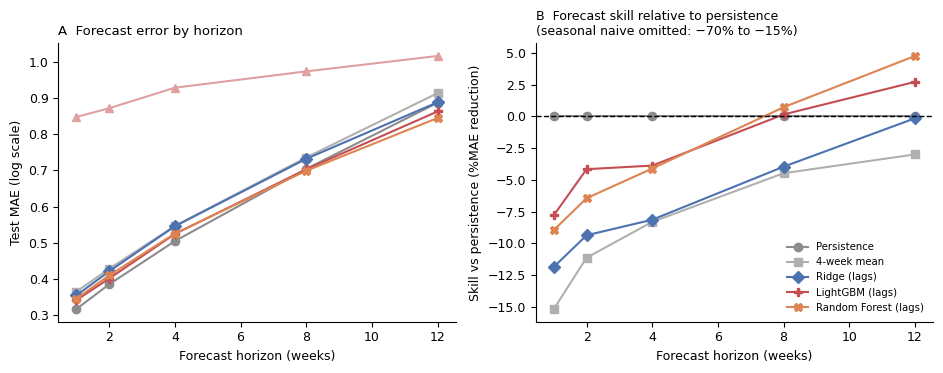

Figure 10 - Forecast scatter (4 weeks ahead)


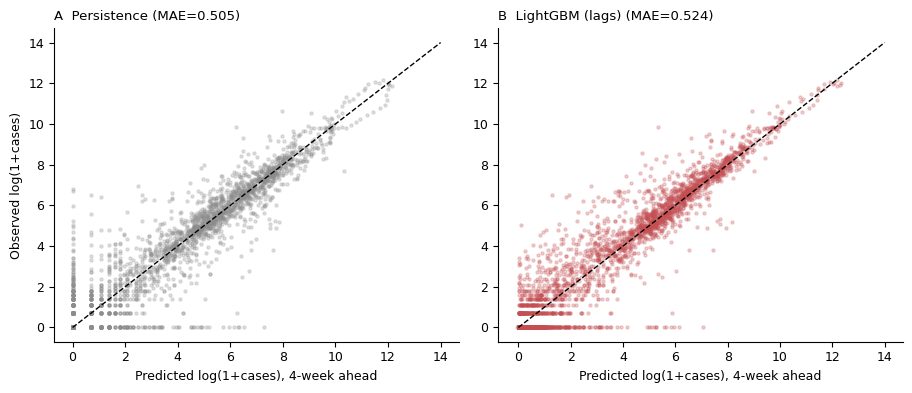

Figure 11 - Example country trajectories


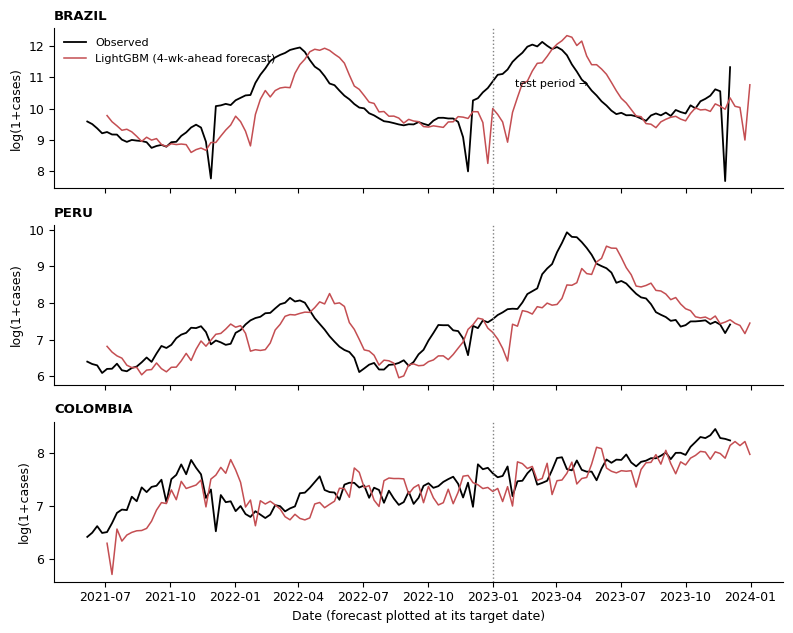

Figure 12 - Outbreak detection and large outbreaks


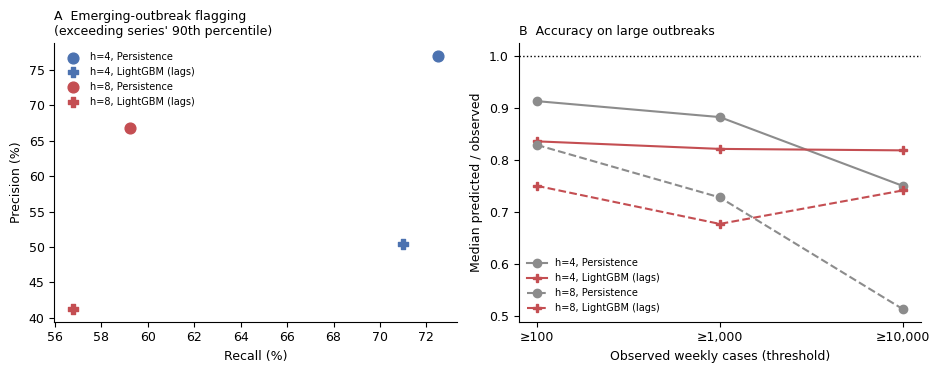

Figure 13 - Cross-scale transfer to Admin1 series


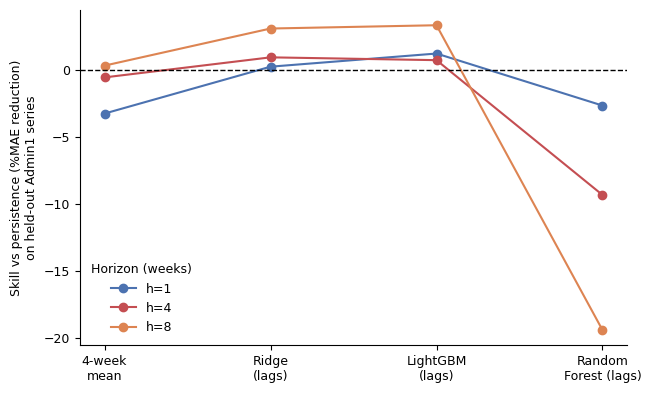

In [98]:
print("Figure 9 - Forecast error and skill by horizon");                  fig9()
print("Figure 10 - Forecast scatter (4 weeks ahead)");                   fig10()
print("Figure 11 - Example country trajectories");                       fig11()
print("Figure 12 - Outbreak detection and large outbreaks");             fig12()
print("Figure 13 - Cross-scale transfer to Admin1 series");              fig13()


## 23. Every number and table used in Section 5 (fc_data.json)

In [99]:
import json
import numpy as np, pandas as pd

m, l = loadp("fc_main.pkl"), loadp("fc_loco.pkl")
ex = loadp("fc_extra.pkl"); sb = loadp("fc_sub_boot.pkl")
ab = pd.read_csv(f"{OUT}/fc_ablate.csv"); sub = pd.read_csv(f"{OUT}/fc_sub.csv"); roll = pd.read_csv(f"{OUT}/fc_roll.csv")
f3 = lambda v: f"{v:.3f}"; f2 = lambda v: f"{v:.2f}"
ci = lambda a, b: f"[{a:+.3f}, {b:+.3f}]"
N, T = {}, {}

MODS = ["Persistence", "4-week mean", "Seasonal naive (52 wk)", "Ridge (lags)", "LightGBM (lags)", "Random Forest (lags)"]
N["n_series_national"] = "100"
N["cut_date"] = "2023-01-01"
rows = []
for h, d in m["horizons"].items():
    row = [str(h), f"{d['n_train']:,}", f"{d['n_test']:,}", str(d["n_countries_test"])]
    for k in MODS:
        v = d["metrics"][k]; row.append(f"{v['MAE']:.3f}"); row.append(f"{v['skill_MAE']*100:+.1f}")
    rows.append(row)
T["main"] = rows
for h in (1, 2, 4, 8, 12):
    d = m["horizons"][h]["metrics"]; bt = m["horizons"][h]["boot"][1]
    for k, tag in [("Persistence", "pers"), ("LightGBM (lags)", "lgb"), ("Ridge (lags)", "ridge"), ("Random Forest (lags)", "rf"), ("Seasonal naive (52 wk)", "seas"), ("4-week mean", "wk4")]:
        N[f"h{h}_{tag}_mae"] = f3(d[k]["MAE"]); N[f"h{h}_{tag}_skill"] = f"{d[k]['skill_MAE']*100:+.1f}"
        N[f"h{h}_{tag}_r2"] = f3(d[k]["R2"]); N[f"h{h}_{tag}_w2"] = f"{d[k]['within_x2']*100:.0f}"
    N[f"h{h}_ntest"] = f"{m['horizons'][h]['n_test']:,}"; N[f"h{h}_nctry"] = str(m["horizons"][h]["n_countries_test"])
    for pair, tag in [("LightGBM (lags) minus Persistence", "lgb_pers"), ("Ridge (lags) minus Persistence", "ridge_pers"),
                      ("Random Forest (lags) minus Persistence", "rf_pers"), ("LightGBM (lags) minus Ridge (lags)", "lgb_ridge"),
                      ("LightGBM (lags) minus Seasonal naive (52 wk)", "lgb_seas")]:
        if pair in bt: N[f"d_h{h}_{tag}"] = ci(bt[pair]["dR2_lo"], bt[pair]["dR2_hi"])

# ---- LOCO ----
for k, tag in [("Persistence", "pers"), ("LightGBM (lags)", "lgb"), ("Ridge (lags)", "ridge"), ("Random Forest (lags)", "rf")]:
    N[f"loco_{tag}_mae"] = f3(l["metrics"][k]["MAE"]); N[f"loco_{tag}_r2"] = f3(l["metrics"][k]["R2"]); N[f"loco_{tag}_skill"] = f"{l['metrics'][k]['skill_MAE']*100:+.1f}"
N["loco_n"] = f"{l['n']:,}"; N["loco_nctry"] = str(l["n_countries"])
N["d_loco_lgb_pers"] = ci(l["boot"][1]["LightGBM (lags) minus Persistence"]["dR2_lo"], l["boot"][1]["LightGBM (lags) minus Persistence"]["dR2_hi"])

# ---- ablation ----
T["ablate"] = [[r.features, f3(r.R2), f3(r.MAE), f"{r.skill_MAE*100:+.1f}"] for r in ab.itertuples()]
N["abl_persist"] = f3(ab[ab.features.str.contains("Persistence-equiv")].R2.iloc[0])
N["abl_short"] = f3(ab[ab.features == "Short lags"].R2.iloc[0])
N["abl_all"] = f3(ab[ab.features == "All lag features"].R2.iloc[0])
N["abl_tabular"] = f3(ab[ab.type == "tabular"].R2.iloc[0])
N["abl_tabular_mae"] = f3(ab[ab.type == "tabular"].MAE.iloc[0])
N["abl_lag_mae_best"] = f3(ab[ab.type == "lag-based"].MAE.min())

# ---- cross-country/scale transfer ----
T["sub"] = []
for h in (1, 4, 8):
    sh = sub[sub.h == h]
    for k in ["Persistence", "4-week mean", "Ridge (lags)", "LightGBM (lags)", "Random Forest (lags)"]:
        r = sh[sh.model == k].iloc[0]
        T["sub"].append([str(h) if k == "Persistence" else "", k, f"{r.MAE:.3f}", f"{r.skill_MAE*100:+.1f}", f"{r.R2:.3f}"])
N["sub_n_units"] = str(sub.n_units.iloc[0]); N["sub_n_countries"] = str(sub.n_countries.iloc[0])
N["sub_n_train_series"] = "88 national series (countries without Admin1 data)"
for h in (1, 4, 8):
    sh = sub[sub.h == h]
    for k, tag in [("Persistence", "pers"), ("LightGBM (lags)", "lgb"), ("Ridge (lags)", "ridge")]:
        r = sh[sh.model == k].iloc[0]; N[f"sub_h{h}_{tag}_mae"] = f3(r.MAE); N[f"sub_h{h}_{tag}_skill"] = f"{r.skill_MAE*100:+.1f}"; N[f"sub_h{h}_{tag}_r2"] = f3(r.R2)
    bt = sb[h][1]
    N[f"d_sub_h{h}_lgb_pers"] = ci(bt["LightGBM (lags) minus Persistence"]["dR2_lo"], bt["LightGBM (lags) minus Persistence"]["dR2_hi"])

# ---- rolling ----
piv = roll.pivot_table(index=["h", "model"], columns="year", values="MAE")
years = sorted(roll.year.unique())
T["roll_cols"] = [str(y) for y in years]
T["roll"] = {}
for h in (1, 4, 8):
    T["roll"][str(h)] = [[k] + [f"{piv.loc[(h, k), y]:.2f}" if (h, k) in piv.index and not pd.isna(piv.loc[(h, k), y]) else "n/a" for y in years] for k in MODS]
N["roll_years"] = f"{years[0]}-{years[-1]}"
lgb_below = sum(1 for h in (1, 4, 8) for y in years if (h, "LightGBM (lags)") in piv.index and (h, "Persistence") in piv.index and piv.loc[(h, "LightGBM (lags)"), y] < piv.loc[(h, "Persistence"), y])
N["roll_lgb_below_n"] = str(lgb_below); N["roll_total_n"] = str(3 * len(years))

# ---- detection / big outbreaks / phase / intervals ----
for h in (4, 8):
    d = ex[f"detect_h{h}"]
    N[f"det_h{h}_n"] = f"{d['n_eval']:,}"; N[f"det_h{h}_prev"] = f"{d['prevalence']*100:.0f}"
    for k, tag in [("Persistence", "pers"), ("LightGBM (lags)", "lgb"), ("Ridge (lags)", "ridge"), ("Random Forest (lags)", "rf"), ("Seasonal naive (52 wk)", "seas")]:
        N[f"det_h{h}_{tag}_auc"] = f3(d[k]["AUROC"]); N[f"det_h{h}_{tag}_rec"] = f"{d[k]['recall']*100:.0f}"; N[f"det_h{h}_{tag}_prec"] = f"{d[k]['precision']*100:.0f}"
    N[f"det_h{h}_dauc"] = ci(*d["dAUROC_LGB_minus_persistence"])
    big = ex[f"big_h{h}"]
    T[f"big_h{h}"] = []
    for thr in (">=100", ">=1000", ">=10000"):
        e = big[thr]
        for k in ("Persistence", "Ridge (lags)", "LightGBM (lags)"):
            T[f"big_h{h}"].append([f"{thr[2:]} (n={e['n']})", k, f2(e[k]["median_ratio"]), f"{e[k]['within_x2']*100:.0f}", f"{e[k]['under']*100:.0f}"])
    N[f"big10k_h{h}_n"] = str(big[">=10000"]["n"])
    N[f"big10k_h{h}_ratio_pers"] = f2(big[">=10000"]["Persistence"]["median_ratio"]); N[f"big10k_h{h}_ratio_lgb"] = f2(big[">=10000"]["LightGBM (lags)"]["median_ratio"])
    N[f"big10k_h{h}_w2_pers"] = f"{big['>=10000']['Persistence']['within_x2']*100:.0f}"; N[f"big10k_h{h}_w2_lgb"] = f"{big['>=10000']['LightGBM (lags)']['within_x2']*100:.0f}"
    ph = ex[f"phase_h{h}"]
    T[f"phase_h{h}"] = [[k, str(v["n"]), f3(v["Persistence"]), f3(v["Ridge (lags)"]), f3(v["LightGBM (lags)"])] for k, v in ph.items()]
    cs = ex[f"country_skill_h{h}"]
    N[f"cskill_h{h}_n"] = str(cs["n_countries"]); N[f"cskill_h{h}_pos"] = f"{cs['share_positive']*100:.0f}"; N[f"cskill_h{h}_med"] = f"{cs['median']*100:+.1f}"
    N[f"cskill_h{h}_q25"] = f"{cs['q25']*100:+.1f}"; N[f"cskill_h{h}_q75"] = f"{cs['q75']*100:+.1f}"
    N[f"cskill_h{h}_best"] = ", ".join(f"{k.title()} ({v*100:+.0f}%)" for k, v in cs["best"].items())
    iv = ex[f"interval_h{h}"]
    N[f"iv_h{h}_cov_lgb"] = f"{iv['LightGBM quantile']['coverage']*100:.0f}"; N[f"iv_h{h}_cov_pers"] = f"{iv['Persistence + empirical residual quantiles']['coverage']*100:.0f}"
    N[f"iv_h{h}_w_lgb"] = f2(iv["LightGBM quantile"]["width"]); N[f"iv_h{h}_w_pers"] = f2(iv["Persistence + empirical residual quantiles"]["width"])

# ---- LightGBM tuning grid (Appendix Table A2) ----
T["lgb_grid"] = [[str(r["num_leaves"]), str(r["learning_rate"]), str(r["n_estimators"]), str(r["min_child_samples"]),
                  f3(r["val_MAE"]) + (" (selected)" if all(r[k] == m["lgb_params"][k] for k in ("num_leaves", "learning_rate", "n_estimators", "min_child_samples")) else "")]
                 for r in m["lgb_search"]]
N["lgb_grid_val_year"] = "2022"

json.dump({"N": N, "T": T}, open(f"{OUT}/fc_data.json", "w"), indent=1, default=str)
print(len(N), "numbers,", list(T), "tables")

281 numbers, ['main', 'ablate', 'sub', 'roll_cols', 'roll', 'big_h4', 'phase_h4', 'big_h8', 'phase_h8', 'lgb_grid'] tables


## 24. External validation on an independent dataset (DengAI) — Section 5.9

This repeats Section 5's temporal hold-out and a leave-city-out test on **DengAI**, a public weekly
dengue dataset for San Juan and Iquitos (DrivenData, 1990-2010) with no connection to OpenDengue.

**How to run.** `dengue_features_train.csv` and `dengue_labels_train.csv` are already part of the Kaggle
dataset `rejuwanshamim/dengue-dataset`; `DENGAI_DIR` is set automatically in the first code cell
(original source: https://www.drivendata.org/competitions/44/dengai-predicting-disease-spread/).

In [100]:
import os
# DENGAI_DIR was already set in the configuration cell (Kaggle input folder); only fall back if it is missing.
if "DENGAI_DIR" not in os.environ:
    os.environ["DENGAI_DIR"] = "/kaggle/input/datasets/rejuwanshamim/dengue-dataset"
print("DENGAI_DIR =", os.environ["DENGAI_DIR"])


DENGAI_DIR = /kaggle/input/datasets/rejuwanshamim/dengue-dataset


In [101]:
import os, sys, json, time
import numpy as np, pandas as pd

DENGAI_DIR = os.environ.get("DENGAI_DIR", "./dengai")


def load_dengai():
    feat = pd.read_csv(os.path.join(DENGAI_DIR, "dengue_features_train.csv"))
    lab = pd.read_csv(os.path.join(DENGAI_DIR, "dengue_labels_train.csv"))
    d = feat.merge(lab, on=["city", "year", "weekofyear"])
    d["start"] = pd.to_datetime(d["week_start_date"])
    d["cases"] = d["total_cases"].astype(float)
    d["unit"] = d["city"].map({"sj": "SAN_JUAN", "iq": "IQUITOS"})
    d["adm_0_name"] = d["unit"]; d["cd"] = "Total"
    return d[["adm_0_name", "unit", "cd", "start", "cases"]].sort_values("start")


def temporal_split_per_city(d, test_frac=0.2):
    tr_idx, te_idx = [], []
    for u, g in d.groupby("unit"):
        g = g.sort_values("date"); n = len(g); cut = int(n * (1 - test_frac))
        tr_idx += list(g.index[:cut]); te_idx += list(g.index[cut:])
    return np.array(sorted(tr_idx)), np.array(sorted(te_idx))


def main():
    t0 = time.time()
    raw = load_dengai()
    print(f"Loaded DengAI: {len(raw)} weekly records, cities {sorted(raw.unit.unique())}, "
          f"{raw.start.min().date()} to {raw.start.max().date()}")
    F = build(raw, H=[1, 4, 8])
    F["date_idx"] = F.index  # for split bookkeeping
    results = {"protocols": {}}

    # ---------------- Protocol 1: per-city chronological hold-out (last 20% of each city) ----------------
    for h in (1, 4, 8):
        feats = feature_sets(h)["All lag features"]
        feats = [c for c in feats if c not in ("case_Suspected", "case_Confirmed", "case_Total")]  # single case def here
        d, X, Xf, dy, y, y0 = prep_xy(F, h, feats)
        tr_idx, te_idx = temporal_split_per_city(d.assign(date=d["date"]))
        tr = np.isin(d.index, tr_idx); te = np.isin(d.index, te_idx)
        P = fit_models(X[tr], Xf[tr], pd.DataFrame({"y": dy[tr]}), X[te], Xf[te],
                          which=("Ridge", "LightGBM"), lgb_params=LGB_DEFAULT)
        preds = {k: y0[te] + v for k, v in P.items()}
        preds.update({k: v[te] for k, v in baselines(d, h).items()})
        met = {k: metrics(y[te], p) for k, p in preds.items()}
        for k, p in preds.items():
            skill = 1 - np.abs(y[te] - p).mean() / np.abs(y[te] - preds["Persistence"]).mean()
            met[k]["skill_MAE"] = float(skill)
        boot = cluster_bootstrap(y[te], preds, d.loc[te, "unit"], B=1000,
                                 pairs=[("LightGBM (lags)", "Persistence"), ("Ridge (lags)", "Persistence")])
        by_city = {}
        for u in ["SAN_JUAN", "IQUITOS"]:
            m = (d.loc[te, "unit"] == u).to_numpy()
            by_city[u] = {k: {"MAE": float(np.abs(y[te][m] - p[m]).mean()),
                              "skill_MAE": float(1 - np.abs(y[te][m] - p[m]).mean() / np.abs(y[te][m] - preds["Persistence"][m]).mean())}
                         for k, p in preds.items()}
        results["protocols"].setdefault("temporal", {})[h] = {"n_train": int(tr.sum()), "n_test": int(te.sum()),
                                                               "metrics": met, "boot": boot, "by_city": by_city}
        print(f"[temporal h={h}] n_test={te.sum()} " + " ".join(f"{k}:MAE={v['MAE']:.2f},skill={v['skill_MAE']*100:+.1f}%" for k, v in met.items()))

    # ---------------- Protocol 2: leave-city-out (train on one city, test on the other) ----------------
    for h in (1, 4, 8):
        feats = feature_sets(h)["All lag features"]
        feats = [c for c in feats if c not in ("case_Suspected", "case_Confirmed", "case_Total")]
        d, X, Xf, dy, y, y0 = prep_xy(F, h, feats)
        for train_city, test_city in [("SAN_JUAN", "IQUITOS"), ("IQUITOS", "SAN_JUAN")]:
            tr = (d["unit"] == train_city).to_numpy(); te = (d["unit"] == test_city).to_numpy()
            P = fit_models(X[tr], Xf[tr], pd.DataFrame({"y": dy[tr]}), X[te], Xf[te],
                              which=("Ridge", "LightGBM"), lgb_params=LGB_DEFAULT)
            preds = {k: y0[te] + v for k, v in P.items()}; preds.update({k: v[te] for k, v in baselines(d, h).items()})
            met = {k: metrics(y[te], p) for k, p in preds.items()}
            for k, p in preds.items():
                met[k]["skill_MAE"] = float(1 - np.abs(y[te] - p).mean() / np.abs(y[te] - preds["Persistence"]).mean())
            results["protocols"].setdefault("leave_city_out", {})[f"h{h}_{train_city}_to_{test_city}"] = {
                "n_train": int(tr.sum()), "n_test": int(te.sum()), "metrics": met}
            print(f"[LCO h={h} {train_city}->{test_city}] " + " ".join(f"{k}:skill={v['skill_MAE']*100:+.1f}%" for k, v in met.items()))

    results["meta"] = {"n_total": int(len(raw)), "cities": sorted(raw.unit.unique().tolist()),
                       "date_min": str(raw.start.min().date()), "date_max": str(raw.start.max().date()),
                       "source": "DrivenData DengAI competition (San Juan, Iquitos); merged features+labels train file"}
    with open(os.path.join(OUT, "dengai_results.json"), "w") as f:
        json.dump(results, f, indent=1, default=str)
    print(f"done in {time.time()-t0:.0f}s -> {OUT}/dengai_results.json")

In [102]:
main()

Loaded DengAI: 1456 weekly records, cities ['IQUITOS', 'SAN_JUAN'], 1990-04-30 to 2010-06-25
[temporal h=1] n_test=287 Ridge (lags):MAE=0.40,skill=+2.1% LightGBM (lags):MAE=0.39,skill=+5.3% Persistence:MAE=0.41,skill=+0.0% 4-week mean:MAE=0.47,skill=-14.4% Seasonal naive (52 wk):MAE=0.95,skill=-128.9% Expanding mean:MAE=0.86,skill=-107.3%
[temporal h=4] n_test=287 Ridge (lags):MAE=0.60,skill=+10.7% LightGBM (lags):MAE=0.59,skill=+13.0% Persistence:MAE=0.67,skill=+0.0% 4-week mean:MAE=0.72,skill=-7.5% Seasonal naive (52 wk):MAE=0.94,skill=-40.2% Expanding mean:MAE=0.86,skill=-27.9%
[temporal h=8] n_test=285 Ridge (lags):MAE=0.72,skill=+20.4% LightGBM (lags):MAE=0.74,skill=+18.4% Persistence:MAE=0.91,skill=+0.0% 4-week mean:MAE=0.93,skill=-3.3% Seasonal naive (52 wk):MAE=0.94,skill=-4.1% Expanding mean:MAE=0.86,skill=+4.8%
[LCO h=1 SAN_JUAN->IQUITOS] Ridge (lags):skill=-23.3% LightGBM (lags):skill=-13.9% Persistence:skill=+0.0% 4-week mean:skill=-3.7% Seasonal naive (52 wk):skill=-132.0%

## 25. Figure and collected numbers for the DengAI comparison

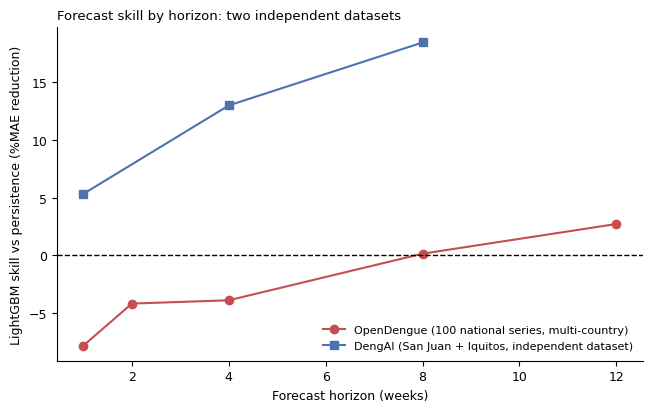

written fig14


In [103]:
import os, json
import matplotlib.pyplot as plt

FIG = os.environ.get("FIG_DIR", os.path.join(OUT, "figs")); os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight"})

m = loadp("fc_main.pkl")
dg = json.load(open(f"{OUT}/dengai_results.json"))

fig, ax = plt.subplots(figsize=(6.6, 4.2))
hs_od = sorted(m["horizons"]); od_skill = [m["horizons"][h]["metrics"]["LightGBM (lags)"]["skill_MAE"] * 100 for h in hs_od]
hs_dg = [1, 4, 8]; dg_skill = [dg["protocols"]["temporal"][str(h)]["metrics"]["LightGBM (lags)"]["skill_MAE"] * 100 for h in hs_dg]
ax.plot(hs_od, od_skill, "-o", color="#C44E52", label="OpenDengue (100 national series, multi-country)")
ax.plot(hs_dg, dg_skill, "-s", color="#4C72B0", label="DengAI (San Juan + Iquitos, independent dataset)")
ax.axhline(0, color="k", ls="--", lw=1)
ax.set_xlabel("Forecast horizon (weeks)"); ax.set_ylabel("LightGBM skill vs persistence (%MAE reduction)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Forecast skill by horizon: two independent datasets", loc="left", fontsize=9.5)
fig.tight_layout(); fig.savefig(f"{FIG}/fig14_dengai_compare.png"); plt.show()
print("written fig14")

In [107]:
import json
import numpy as np

r = json.load(open(f"{OUT}/dengai_results.json"))
f3 = lambda v: f"{v:.3f}"; f2 = lambda v: f"{v:.2f}"; f1 = lambda v: f"{v:.1f}"
ci = lambda lo, hi: f"[{lo:+.3f}, {hi:+.3f}]"
N, T = {}, {}

meta = r["meta"]
N["dengai_n"] = f"{meta['n_total']:,}"; N["dengai_date0"] = meta["date_min"]; N["dengai_date1"] = meta["date_max"]

MODS = ["Persistence", "4-week mean", "Seasonal naive (52 wk)", "Ridge (lags)", "LightGBM (lags)"]
T["temporal"] = []
for h in ("1", "4", "8"):
    d = r["protocols"]["temporal"][h]
    row = [h, f"{d['n_train']:,}", f"{d['n_test']:,}"]
    for m in MODS:
        row += [f2(d["metrics"][m]["MAE"]), f"{d['metrics'][m]['skill_MAE']*100:+.1f}"]
    T["temporal"].append(row)
    for m, tag in [("Persistence", "pers"), ("Ridge (lags)", "ridge"), ("LightGBM (lags)", "lgb")]:
        N[f"dg_h{h}_{tag}_mae"] = f2(d["metrics"][m]["MAE"]); N[f"dg_h{h}_{tag}_skill"] = f"{d['metrics'][m]['skill_MAE']*100:+.1f}"
        N[f"dg_h{h}_{tag}_r2"] = f3(d["metrics"][m]["R2"])
    bt = d["boot"][1]
    for pair, tag in [("LightGBM (lags) minus Persistence", "lgb_pers"), ("Ridge (lags) minus Persistence", "ridge_pers")]:
        N[f"dg_d_h{h}_{tag}"] = ci(bt[pair]["dR2_lo"], bt[pair]["dR2_hi"])
        N[f"dg_dmae_h{h}_{tag}"] = ci(bt[pair]["dMAE_lo"], bt[pair]["dMAE_hi"])
    for city in ("SAN_JUAN", "IQUITOS"):
        bc = d["by_city"][city]
        N[f"dg_h{h}_{city.lower()}_lgb_skill"] = f"{bc['LightGBM (lags)']['skill_MAE']*100:+.1f}"

T["lco"] = []
for h in (1, 4, 8):
    for train_c, test_c in [("SAN_JUAN", "IQUITOS"), ("IQUITOS", "SAN_JUAN")]:
        d = r["protocols"]["leave_city_out"][f"h{h}_{train_c}_to_{test_c}"]
        T["lco"].append([str(h), f"{train_c.title().replace('_',' ')} \u2192 {test_c.title().replace('_',' ')}",
                         f"{d['metrics']['LightGBM (lags)']['skill_MAE']*100:+.1f}", f"{d['metrics']['Ridge (lags)']['skill_MAE']*100:+.1f}"])
N["dg_lco_worst"] = f"{min(r['protocols']['leave_city_out'][k]['metrics']['LightGBM (lags)']['skill_MAE'] for k in r['protocols']['leave_city_out'])*100:.0f}"
N["dg_lco_best"] = f"{max(r['protocols']['leave_city_out'][k]['metrics']['LightGBM (lags)']['skill_MAE'] for k in r['protocols']['leave_city_out'])*100:.0f}"

json.dump({"N": N, "T": T}, open(f"{OUT}/dengai_data.json", "w"), indent=1, default=str)
print(len(N), "numbers,", list(T), "tables")

50 numbers, ['temporal', 'lco'] tables


## 26. Package the results (Kaggle)

Files in `/kaggle/working` are stored as the notebook's **Output** when you use *Save Version → Save & Run All*
(and can be downloaded from the Output tab). This cell also zips `results/` into one file.


In [108]:
import shutil
zip_path = shutil.make_archive("/kaggle/working/dengue_results", "zip", OUT)
print("created", zip_path)
print("Download it from the notebook's Output tab (right sidebar -> Output) after 'Save Version'.")


created /kaggle/working/dengue_results.zip
Download it from the notebook's Output tab (right sidebar -> Output) after 'Save Version'.
